In [1]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/thedevastator/unlock-profits-with-e-commerce-sales-data/Amazon Sale Report.csv
/kaggle/input/datasets/thedevastator/unlock-profits-with-e-commerce-sales-data/Cloud Warehouse Compersion Chart.csv
/kaggle/input/datasets/thedevastator/unlock-profits-with-e-commerce-sales-data/Expense IIGF.csv
/kaggle/input/datasets/thedevastator/unlock-profits-with-e-commerce-sales-data/International sale Report.csv
/kaggle/input/datasets/thedevastator/unlock-profits-with-e-commerce-sales-data/May-2022.csv
/kaggle/input/datasets/thedevastator/unlock-profits-with-e-commerce-sales-data/P  L March 2021.csv
/kaggle/input/datasets/thedevastator/unlock-profits-with-e-commerce-sales-data/Sale Report.csv


In [2]:
import pandas as pd

file_path = '/kaggle/input/datasets/thedevastator/unlock-profits-with-e-commerce-sales-data/Amazon Sale Report.csv'

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Shape: (128975, 24)

First 5 Rows:


/tmp/ipykernel_48/2066317111.py:5: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN



Column Names:
['index', 'Order ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel ', 'ship-service-level', 'Style', 'SKU', 'Category', 'Size', 'ASIN', 'Courier Status', 'Qty', 'currency', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'ship-country', 'promotion-ids', 'B2B', 'fulfilled-by', 'Unnamed: 22']

Data Types:
index                   int64
Order ID               object
Date                   object
Status                 object
Fulfilment             object
Sales Channel          object
ship-service-level     object
Style                  object
SKU                    object
Category               object
Size                   object
ASIN                   object
Courier Status         object
Qty                     int64
currency               object
Amount                float64
ship-city              object
ship-state             object
ship-postal-code      float64
ship-country           object
promotion-ids          object
B2B                      bool
fulfilled

In [3]:
# Phase 1: Data Quality Audit

raw_df = pd.read_csv(file_path, low_memory=False)

print("1. MISSING VALUES")
display(raw_df.isnull().sum().to_frame("Missing Values"))

print("\n2. DUPLICATE RECORDS")
print("Duplicate rows:", raw_df.duplicated().sum())
print("Unique orders:", raw_df["Order ID"].nunique())

print("\n3. ORDER STATUS")
display(raw_df["Status"].value_counts())

print("\n4. DATE RANGE")
dates = pd.to_datetime(
    raw_df["Date"], format="%m-%d-%y", errors="coerce"
)
print("Invalid dates:", dates.isna().sum())
print("Start date:", dates.min())
print("End date:", dates.max())

print("\n5. QUANTITY")
display(raw_df["Qty"].describe())

print("\n6. AMOUNT")
display(raw_df["Amount"].describe())

1. MISSING VALUES


,Missing Values
index,0
Order ID,0
Date,0
Status,0
Fulfilment,0
Sales Channel,0
ship-service-level,0
Style,0
SKU,0
Category,0



2. DUPLICATE RECORDS
Duplicate rows: 0
Unique orders: 120378

3. ORDER STATUS


Status
Shipped                          77804
Shipped - Delivered to Buyer     28769
Cancelled                        18332
Shipped - Returned to Seller      1953
Shipped - Picked Up                973
Pending                            658
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipping                             8
Shipped - Lost in Transit            5
Shipped - Damaged                    1
Name: count, dtype: int64


4. DATE RANGE
Invalid dates: 0
Start date: 2022-03-31 00:00:00
End date: 2022-06-29 00:00:00

5. QUANTITY


count    128975.000000
mean          0.904431
std           0.313354
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          15.000000
Name: Qty, dtype: float64


6. AMOUNT


count    121180.000000
mean        648.561465
std         281.211687
min           0.000000
25%         449.000000
50%         605.000000
75%         788.000000
max        5584.000000
Name: Amount, dtype: float64

In [4]:
print("1. ZERO QUANTITY RECORDS")
print("Count:", (raw_df["Qty"] == 0).sum())

print("\n2. ZERO AMOUNT RECORDS")
print("Count:", (raw_df["Amount"] == 0).sum())

print("\n3. MISSING AMOUNT BY ORDER STATUS")
display(
    raw_df.groupby("Status")["Amount"]
    .apply(lambda x: x.isna().sum())
    .sort_values(ascending=False)
)

print("\n4. ORDER IDs WITH MULTIPLE ROWS")
display(
    raw_df["Order ID"].value_counts().value_counts()
    .sort_index()
    .to_frame("Number of Orders")
    .rename_axis("Rows per Order")
)

print("\n5. UNNAMED COLUMN VALUES")
display(raw_df["Unnamed: 22"].value_counts(dropna=False).head(10))

print("\n6. INDEX VALIDATION")
print("Sequential index:", raw_df["index"].equals(pd.Series(range(len(raw_df)))))

print("\n7. CURRENCY VALUES")
display(raw_df["currency"].value_counts(dropna=False))

1. ZERO QUANTITY RECORDS
Count: 12807

2. ZERO AMOUNT RECORDS
Count: 2343

3. MISSING AMOUNT BY ORDER STATUS


Status
Cancelled                        7566
Shipped                           208
Shipped - Delivered to Buyer        8
Shipping                            8
Shipped - Returned to Seller        3
Pending                             2
Pending - Waiting for Pick Up       0
Shipped - Damaged                   0
Shipped - Lost in Transit           0
Shipped - Picked Up                 0
Shipped - Out for Delivery          0
Shipped - Rejected by Buyer         0
Shipped - Returning to Seller       0
Name: Amount, dtype: int64


4. ORDER IDs WITH MULTIPLE ROWS


,Number of Orders
Rows per Order,
1,113532
2,5655
3,859
4,218
5,68
6,16
7,13
8,7
9,5



5. UNNAMED COLUMN VALUES


Unnamed: 22
False    79925
NaN      49050
Name: count, dtype: int64


6. INDEX VALIDATION
Sequential index: True

7. CURRENCY VALUES


currency
INR    121180
NaN      7795
Name: count, dtype: int64

In [5]:
print("1. ZERO QUANTITY BY STATUS")
display(
    raw_df[raw_df["Qty"] == 0]["Status"].value_counts()
)

print("\n2. ZERO AMOUNT BY STATUS")
display(
    raw_df[raw_df["Amount"] == 0]["Status"].value_counts()
)

print("\n3. ZERO QUANTITY AND ZERO AMOUNT")
print(
    "Both zero:",
    ((raw_df["Qty"] == 0) & (raw_df["Amount"] == 0)).sum()
)

print("\n4. SAMPLE ZERO QUANTITY RECORDS")
display(raw_df[raw_df["Qty"] == 0].head(10))

print("\n5. SAMPLE ZERO AMOUNT RECORDS")
display(raw_df[raw_df["Amount"] == 0].head(10))

print("\n6. UNNAMED COLUMN AGAINST ORDER STATUS")
display(pd.crosstab(
    raw_df["Status"],
    raw_df["Unnamed: 22"],
    dropna=False
))

print("\n7. FULFILMENT TYPES")
display(raw_df["Fulfilment"].value_counts(dropna=False))

1. ZERO QUANTITY BY STATUS


Status
Cancelled                       12701
Shipped                            93
Shipped - Delivered to Buyer        8
Shipped - Returned to Seller        3
Pending                             2
Name: count, dtype: int64


2. ZERO AMOUNT BY STATUS


Status
Shipped                          1518
Shipped - Delivered to Buyer      716
Shipped - Returned to Seller       51
Shipped - Picked Up                28
Pending                            17
Pending - Waiting for Pick Up       9
Shipped - Lost in Transit           2
Shipped - Returning to Seller       2
Name: count, dtype: int64


3. ZERO QUANTITY AND ZERO AMOUNT
Both zero: 0

4. SAMPLE ZERO QUANTITY RECORDS


,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
8,8,407-5443024-5233168,04-30-22,Cancelled,Amazon,Amazon.in,Expedited,SET200,SET200-KR-NP-A-XXXL,Set,...,NaN,NaN,HYDERABAD,TELANGANA,500008.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,NaN
23,23,404-6019946-2909948,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET291,SET291-KR-PP-M,Set,...,INR,570.48,pune,MAHARASHTRA,411044.0,IN,NaN,False,Easy Ship,NaN
29,29,404-5933402-8801952,04-30-22,Cancelled,Merchant,Amazon.in,Standard,JNE2132,JNE2132-KR-398-XXXL,kurta,...,NaN,NaN,GUWAHATI,ASSAM,781003.0,IN,NaN,False,Easy Ship,NaN
65,65,171-4137548-0481151,04-30-22,Cancelled,Amazon,Amazon.in,Expedited,JNE3373,JNE3373-KR-XXL,kurta,...,NaN,NaN,Dahod,Gujarat,389151.0,IN,NaN,False,NaN,NaN
83,83,404-6522553-9345930,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET377,SET377-KR-NP-M,Set,...,INR,1105.36,DEHRADUN,UTTARAKHAND,248001.0,IN,NaN,False,Easy Ship,NaN
84,84,403-9950518-0349133,04-30-22,Cancelled,Amazon,Amazon.in,Expedited,JNE3510,JNE3510-KR-M,kurta,...,NaN,NaN,HYDERABAD,TELANGANA,500072.0,IN,NaN,False,NaN,NaN
95,95,405-9112089-3379536,04-30-22,Cancelled,Amazon,Amazon.in,Expedited,JNE3405,JNE3405-KR-L,kurta,...,NaN,NaN,PUNE,MAHARASHTRA,411046.0,IN,NaN,False,NaN,NaN
101,101,402-7841951-1872363,04-30-22,Cancelled,Amazon,Amazon.in,Expedited,SET347,SET347-KR-NP-S,Set,...,NaN,NaN,NEW DELHI,DELHI,110036.0,IN,NaN,False,NaN,NaN


... (2 outputs left out)


6. UNNAMED COLUMN AGAINST ORDER STATUS


Unnamed: 22,False,NaN
Status,,
Cancelled,11208,7124
Pending,657,1
Pending - Waiting for Pick Up,281,0
Shipped,48854,28950
Shipped - Damaged,1,0
Shipped - Delivered to Buyer,16702,12067
Shipped - Lost in Transit,3,2
Shipped - Out for Delivery,34,1
Shipped - Picked Up,969,4



7. FULFILMENT TYPES


Fulfilment
Amazon      89698
Merchant    39277
Name: count, dtype: int64

In [6]:
print("1. UNNAMED COLUMN VS B2B")
display(pd.crosstab(
    raw_df["B2B"],
    raw_df["Unnamed: 22"],
    dropna=False
))

print("\n2. ZERO QUANTITY WITH NON-CANCELLED STATUS")
display(
    raw_df[
        (raw_df["Qty"] == 0) &
        (raw_df["Status"] != "Cancelled")
    ][["Order ID", "Status", "Qty", "Amount", "Category"]].head(20)
)

print("\n3. MISSING AMOUNT WITH POSITIVE QUANTITY")
display(
    raw_df[
        raw_df["Amount"].isna() & (raw_df["Qty"] > 0)
    ][["Order ID", "Status", "Qty", "Category"]]
    .head(10)
)

print("\n4. NEGATIVE VALUES")
print("Negative quantity:", (raw_df["Qty"] < 0).sum())
print("Negative amount:", (raw_df["Amount"] < 0).sum())

1. UNNAMED COLUMN VS B2B


Unnamed: 22,False,NaN
B2B,,
False,79403,48701
True,522,349



2. ZERO QUANTITY WITH NON-CANCELLED STATUS


,Order ID,Status,Qty,Amount,Category
1615,405-7790745-1369118,Shipped,0,NaN,kurta
1989,171-9673855-2321133,Shipped,0,NaN,Set
2424,404-7478762-7926753,Shipped,0,NaN,Set
2819,404-0814480-8157169,Shipped,0,NaN,kurta
9255,405-1892033-5435562,Shipped,0,NaN,Set
11145,404-7498280-7477149,Shipped,0,NaN,Set
15881,406-5281014-6299540,Shipped,0,NaN,Top
16191,408-3851867-4615501,Shipped,0,NaN,kurta
16599,403-8676035-5065939,Shipped,0,NaN,Set
18336,405-1252351-8764324,Shipped,0,NaN,Set



3. MISSING AMOUNT WITH POSITIVE QUANTITY


,Order ID,Status,Qty,Category
937,S02-5278980-4327051,Shipped,15,Blouse
1057,S02-9107114-0460608,Shipped,2,Set
3631,S02-1006261-5356758,Shipped,9,kurta
3632,S02-3681731-6111841,Shipped,1,kurta
3634,S02-1926028-4838217,Shipped,1,kurta
3636,S02-6828927-1180856,Shipped,13,kurta
3637,S02-3409426-0744131,Shipped,2,Blouse
3886,S02-8357726-8633940,Shipped,1,Set
3887,S02-6358630-3384547,Shipped,1,Blouse
3888,S02-8920429-3367507,Shipped,1,Set



4. NEGATIVE VALUES
Negative quantity: 0
Negative amount: 0


In [7]:
# Create a separate working copy
df_clean = raw_df.copy()

# Remove unnecessary export columns
df_clean = df_clean.drop(
    columns=["index", "Unnamed: 22"]
)

# Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

# Convert date into proper datetime format
df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    format="%m-%d-%y",
    errors="coerce"
)

# Preserve postal codes as strings
df_clean["ship_postal_code"] = (
    df_clean["ship_postal_code"]
    .astype("Int64")
    .astype("string")
)

print("Original shape:", raw_df.shape)
print("Cleaned shape:", df_clean.shape)

print("\nCleaned columns:")
print(df_clean.columns.tolist())

print("\nData types:")
print(df_clean.dtypes)

Original shape: (128975, 24)
Cleaned shape: (128975, 22)

Cleaned columns:
['order_id', 'date', 'status', 'fulfilment', 'sales_channel', 'ship_service_level', 'style', 'sku', 'category', 'size', 'asin', 'courier_status', 'qty', 'currency', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'ship_country', 'promotion_ids', 'b2b', 'fulfilled_by']

Data types:
order_id                      object
date                  datetime64[ns]
status                        object
fulfilment                    object
sales_channel                 object
ship_service_level            object
style                         object
sku                           object
category                      object
size                          object
asin                          object
courier_status                object
qty                            int64
currency                      object
amount                       float64
ship_city                     object
ship_state                    object
ship_

In [8]:
missing_report = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().mean() * 100
    ).round(2),
    "Data_Type": df_clean.dtypes.astype(str)
})

display(
    missing_report[
        missing_report["Missing_Count"] > 0
    ].sort_values("Missing_Percentage", ascending=False)
)

,Missing_Count,Missing_Percentage,Data_Type
fulfilled_by,89698,69.55,object
promotion_ids,49153,38.11,object
currency,7795,6.04,object
amount,7795,6.04,float64
courier_status,6872,5.33,object
ship_state,33,0.03,object
ship_city,33,0.03,object
ship_country,33,0.03,object
ship_postal_code,33,0.03,string


In [9]:
print("Unique values in important columns")

for col in [
    "currency", "courier_status", "fulfilled_by",
    "ship_country", "sales_channel", "fulfilment"
]:
    print(f"\n{col}:")
    display(df_clean[col].value_counts(dropna=False).head(15))

Unique values in important columns

currency:


currency
INR    121180
NaN      7795
Name: count, dtype: int64


courier_status:


courier_status
Shipped      109487
NaN            6872
Unshipped      6681
Cancelled      5935
Name: count, dtype: int64


fulfilled_by:


fulfilled_by
NaN          89698
Easy Ship    39277
Name: count, dtype: int64

... (2 outputs left out)


sales_channel:


sales_channel
Amazon.in     128851
Non-Amazon       124
Name: count, dtype: int64


fulfilment:


fulfilment
Amazon      89698
Merchant    39277
Name: count, dtype: int64

In [10]:
print("1. MISSING AMOUNT BY FULFILMENT")
display(pd.crosstab(
    df_clean["fulfilment"],
    df_clean["amount"].isna()
))

print("\n2. MISSING AMOUNT BY STATUS")
display(pd.crosstab(
    df_clean["status"],
    df_clean["amount"].isna()
))

print("\n3. MISSING COURIER STATUS BY FULFILMENT")
display(pd.crosstab(
    df_clean["fulfilment"],
    df_clean["courier_status"].isna()
))

print("\n4. MISSING SHIPPING LOCATION")
print(
    "Missing city:", df_clean["ship_city"].isna().sum(),
    "\nMissing state:", df_clean["ship_state"].isna().sum(),
    "\nMissing postal code:", df_clean["ship_postal_code"].isna().sum()
)

print("\n5. FULL MISSING VALUE REPORT")
display(missing_report)

1. MISSING AMOUNT BY FULFILMENT


amount,False,True
fulfilment,,
Amazon,83639,6059
Merchant,37541,1736



2. MISSING AMOUNT BY STATUS


amount,False,True
status,,
Cancelled,10766,7566
Pending,656,2
Pending - Waiting for Pick Up,281,0
Shipped,77596,208
Shipped - Damaged,1,0
Shipped - Delivered to Buyer,28761,8
Shipped - Lost in Transit,5,0
Shipped - Out for Delivery,35,0
Shipped - Picked Up,973,0



3. MISSING COURIER STATUS BY FULFILMENT


courier_status,False,True
fulfilment,,
Amazon,89698,0
Merchant,32405,6872



4. MISSING SHIPPING LOCATION
Missing city: 33 
Missing state: 33 
Missing postal code: 33

5. FULL MISSING VALUE REPORT


,Missing_Count,Missing_Percentage,Data_Type
order_id,0,0.00,object
date,0,0.00,datetime64[ns]
status,0,0.00,object
fulfilment,0,0.00,object
sales_channel,0,0.00,object
ship_service_level,0,0.00,object
style,0,0.00,object
sku,0,0.00,object
category,0,0.00,object
size,0,0.00,object


In [12]:
# Create data quality flags
df_clean["amount_missing"] = df_clean["amount"].isna()

df_clean["currency_missing"] = df_clean["currency"].isna()

df_clean["courier_status_missing"] = (
    df_clean["courier_status"].isna()
)

df_clean["zero_quantity"] = df_clean["qty"].eq(0)

df_clean["zero_amount"] = df_clean["amount"].eq(0)

df_clean["location_missing"] = (
    df_clean[
        ["ship_city", "ship_state",
         "ship_postal_code", "ship_country"]
    ].isna().any(axis=1)
)

# Quality summary
quality_flags = [
    "amount_missing",
    "currency_missing",
    "courier_status_missing",
    "zero_quantity",
    "zero_amount",
    "location_missing"
]

display(
    df_clean[quality_flags]
    .sum()
    .to_frame("Flagged_Records")
)

print("\nUpdated dataset shape:", df_clean.shape)
print("Original records preserved:", len(df_clean) == len(raw_df))

,Flagged_Records
amount_missing,7795
currency_missing,7795
courier_status_missing,6872
zero_quantity,12807
zero_amount,2343
location_missing,33



Updated dataset shape: (128975, 28)
Original records preserved: True


In [13]:
print("1. MULTIPLE ROWS PER ORDER")
order_rows = df_clean.groupby("order_id").agg(
    row_count=("order_id", "size"),
    unique_skus=("sku", "nunique"),
    unique_styles=("style", "nunique"),
    total_qty=("qty", "sum"),
    total_amount=("amount", "sum")
)

display(order_rows[order_rows["row_count"] > 1].head(15))

print("\n2. ORDER-LEVEL STRUCTURE")
print("Total order IDs:", df_clean["order_id"].nunique())
print("Orders with multiple rows:", (order_rows["row_count"] > 1).sum())
print("Orders with multiple SKUs:", (order_rows["unique_skus"] > 1).sum())

print("\n3. SAME ORDER ID WITH DIFFERENT STATUSES")
status_counts = df_clean.groupby("order_id")["status"].nunique()
print("Orders with multiple statuses:", (status_counts > 1).sum())

print("\n4. SAME ORDER ID WITH DIFFERENT AMOUNTS")
amount_counts = df_clean.groupby("order_id")["amount"].nunique()
print("Orders with multiple amount values:", (amount_counts > 1).sum())

1. MULTIPLE ROWS PER ORDER


,row_count,unique_skus,unique_styles,total_qty,total_amount
order_id,,,,,
171-0012693-2893106,2,2,2,0,1015.24
171-0014231-7760344,2,2,2,2,2214.00
171-0015435-1981904,2,2,2,2,976.00
171-0019960-6156301,2,2,2,2,1261.00
171-0031114-0715560,2,2,2,2,634.00
171-0032816-1151573,2,2,2,2,788.00
171-0035451-9642759,2,2,2,2,1123.00
171-0036605-7601963,2,2,2,2,1838.00
171-0040661-6643541,2,2,2,1,999.00



2. ORDER-LEVEL STRUCTURE
Total order IDs: 120378
Orders with multiple rows: 6846
Orders with multiple SKUs: 6840

3. SAME ORDER ID WITH DIFFERENT STATUSES
Orders with multiple statuses: 0

4. SAME ORDER ID WITH DIFFERENT AMOUNTS
Orders with multiple amount values: 5730


In [14]:
print("1. REPEATED ORDER + SKU COMBINATIONS")

order_sku = df_clean.groupby(
    ["order_id", "sku"]
).size()

print("Repeated order-SKU combinations:", (order_sku > 1).sum())

print("\n2. SAMPLE ORDERS WITH MULTIPLE PRODUCTS")

sample_orders = (
    df_clean.groupby("order_id")
    .filter(lambda x: len(x) > 1)
    .head(20)
)

display(sample_orders[
    ["order_id", "sku", "category", "qty", "amount", "status"]
])

print("\n3. AMOUNT CONSISTENCY WITHIN ORDERS")

amount_check = df_clean.groupby("order_id").agg(
    rows=("order_id", "size"),
    amount_values=("amount", "nunique"),
    amount_sum=("amount", "sum"),
    amount_max=("amount", "max")
)

display(amount_check[amount_check["rows"] > 1].head(15))

print("\n4. ORDER AMOUNT SUMMARY")
print("Orders with all amounts missing:",
      df_clean.groupby("order_id")["amount"].apply(
          lambda x: x.isna().all()
      ).sum())

1. REPEATED ORDER + SKU COMBINATIONS
Repeated order-SKU combinations: 7

2. SAMPLE ORDERS WITH MULTIPLE PRODUCTS


,order_id,sku,category,qty,amount,status
37,403-4367956-2849158,JNE3787-KR-S,kurta,1,487.00,Shipped
38,403-4367956-2849158,JNE3543-KR-S,kurta,1,368.00,Shipped
61,404-2262140-4696366,JNE2270-KR-487-A-M,kurta,1,518.00,Shipped
62,404-2262140-4696366,JNE3579-KR-M,kurta,1,295.00,Shipped
79,408-4069830-3819562,SET288-KR-NP-XXXL,Set,1,684.00,Shipped
80,408-4069830-3819562,SET394-KR-NP-XXXL,Set,1,1281.00,Shipped
81,408-4069830-3819562,SET397-KR-NP-XXXL,Set,1,1186.00,Shipped
105,405-5257740-5301158,SET154-KR-NP-XL,Set,1,832.00,Shipped - Delivered to Buyer
106,405-5257740-5301158,JNE3439-KR-XL,kurta,1,399.00,Shipped - Delivered to Buyer
116,403-0104882-7373900,JNE3861-DR-XXL,Western Dress,1,791.00,Cancelled



3. AMOUNT CONSISTENCY WITHIN ORDERS


,rows,amount_values,amount_sum,amount_max
order_id,,,,
171-0012693-2893106,2,2,1015.24,538.1
171-0014231-7760344,2,2,2214.00,1364.0
171-0015435-1981904,2,2,976.00,517.0
171-0019960-6156301,2,2,1261.00,635.0
171-0031114-0715560,2,2,634.00,333.0
171-0032816-1151573,2,2,788.00,450.0
171-0035451-9642759,2,2,1123.00,563.0
171-0036605-7601963,2,2,1838.00,988.0
171-0040661-6643541,2,1,999.00,999.0



4. ORDER AMOUNT SUMMARY
Orders with all amounts missing: 7348


In [15]:
# Inspect all repeated Order ID + SKU combinations

repeated_skus = df_clean[
    df_clean.duplicated(
        subset=["order_id", "sku"],
        keep=False
    )
].sort_values(["order_id", "sku"])

display(
    repeated_skus[
        ["order_id", "sku", "style", "category",
         "qty", "amount", "status", "date"]
    ]
)

print("Repeated SKU rows:", len(repeated_skus))
print(
    "Affected orders:",
    repeated_skus["order_id"].nunique()
)

print("\nCheck whether repeated rows are identical:")
print(
    "Exact duplicates within these records:",
    repeated_skus.duplicated().sum()
)

,order_id,sku,style,category,qty,amount,status,date
85790,171-3249942-2207542,SET323-KR-NP-XL,SET323,Set,1,939.0,Shipped,2022-05-03
85791,171-3249942-2207542,SET323-KR-NP-XL,SET323,Set,1,939.0,Shipped,2022-05-03
79844,171-9628368-5329958,J0329-KR-L,J0329,kurta,0,NaN,Cancelled,2022-05-07
79845,171-9628368-5329958,J0329-KR-L,J0329,kurta,0,NaN,Cancelled,2022-05-07
86418,405-8669298-3850736,MEN5025-KR-XXXL,MEN5025,kurta,1,533.0,Shipped,2022-05-03
86419,405-8669298-3850736,MEN5025-KR-XXXL,MEN5025,kurta,1,533.0,Shipped,2022-05-03
30660,406-0372545-6086735,SET197-KR-NP-L,SET197,Set,0,NaN,Cancelled,2022-04-12
30661,406-0372545-6086735,SET197-KR-NP-L,SET197,Set,0,NaN,Cancelled,2022-04-12
98954,407-4853873-4978725,J0230-SKD-M,J0230,Set,1,1163.0,Shipped,2022-06-22
98955,407-4853873-4978725,J0230-SKD-M,J0230,Set,1,1163.0,Shipped,2022-06-22


Repeated SKU rows: 14
Affected orders: 7

Check whether repeated rows are identical:
Exact duplicates within these records: 6


In [17]:
# Check repeated rows across all retained columns
duplicate_check = (
    repeated_skus
    .groupby(["order_id", "sku"])
    .agg(
        rows=("order_id", "size"),
        unique_values=("amount", "nunique"),
        unique_quantities=("qty", "nunique"),
        unique_statuses=("status", "nunique"),
        unique_full_records=("order_id", "size")
    )
)

print("Repeated combinations:")
display(duplicate_check)

print("\nExact duplicate rows across all columns:")
print(df_clean.duplicated().sum())

print("\nInspect the repeated order with different values:")
display(
    repeated_skus[
        repeated_skus["order_id"] ==
        "407-8364731-6449117"
    ]
)

Repeated combinations:


,,rows,unique_values,unique_quantities,unique_statuses,unique_full_records
order_id,sku,,,,,
171-3249942-2207542,SET323-KR-NP-XL,2,1,1,1,2
171-9628368-5329958,J0329-KR-L,2,0,1,1,2
405-8669298-3850736,MEN5025-KR-XXXL,2,1,1,1,2
406-0372545-6086735,SET197-KR-NP-L,2,0,1,1,2
407-4853873-4978725,J0230-SKD-M,2,1,1,1,2
407-8364731-6449117,JNE3769-KR-L,2,1,2,1,2
408-0373839-4433120,JNE3501-KR-M,2,0,1,1,2



Exact duplicate rows across all columns:
6

Inspect the repeated order with different values:


,order_id,date,status,fulfilment,sales_channel,ship_service_level,style,sku,category,size,...,ship_country,promotion_ids,b2b,fulfilled_by,amount_missing,currency_missing,courier_status_missing,zero_quantity,zero_amount,location_missing
52330,407-8364731-6449117,2022-05-29,Shipped,Amazon,Amazon.in,Expedited,JNE3769,JNE3769-KR-L,kurta,L,...,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,True,True,False,True,False,False
52333,407-8364731-6449117,2022-05-29,Shipped,Amazon,Amazon.in,Expedited,JNE3769,JNE3769-KR-L,kurta,L,...,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,False,False,False,False,False,False


In [18]:
# Identify every exact duplicate row
exact_duplicates = df_clean[
    df_clean.duplicated(keep=False)
].sort_values(["order_id", "sku"])

print("Rows involved in exact duplicates:",
      len(exact_duplicates))

print("Extra duplicate rows:",
      df_clean.duplicated().sum())

print("\nAffected order IDs:")
display(
    exact_duplicates[
        ["order_id", "sku", "qty", "amount", "status"]
    ]
)

print("\nNumber of affected orders:",
      exact_duplicates["order_id"].nunique())

Rows involved in exact duplicates: 12
Extra duplicate rows: 6

Affected order IDs:


,order_id,sku,qty,amount,status
85790,171-3249942-2207542,SET323-KR-NP-XL,1,939.0,Shipped
85791,171-3249942-2207542,SET323-KR-NP-XL,1,939.0,Shipped
79844,171-9628368-5329958,J0329-KR-L,0,NaN,Cancelled
79845,171-9628368-5329958,J0329-KR-L,0,NaN,Cancelled
86418,405-8669298-3850736,MEN5025-KR-XXXL,1,533.0,Shipped
86419,405-8669298-3850736,MEN5025-KR-XXXL,1,533.0,Shipped
30660,406-0372545-6086735,SET197-KR-NP-L,0,NaN,Cancelled
30661,406-0372545-6086735,SET197-KR-NP-L,0,NaN,Cancelled
98954,407-4853873-4978725,J0230-SKD-M,1,1163.0,Shipped
98955,407-4853873-4978725,J0230-SKD-M,1,1163.0,Shipped



Number of affected orders: 6


In [19]:
# Preserve df_clean; create a separate deduplicated dataset
df_analysis = df_clean.drop_duplicates().copy()

print("Original working dataset:", df_clean.shape)
print("Analysis dataset:", df_analysis.shape)

print("\nDuplicate rows removed:",
      len(df_clean) - len(df_analysis))

print("Remaining exact duplicates:",
      df_analysis.duplicated().sum())

print("\nUnique orders before:",
      df_clean["order_id"].nunique())

print("Unique orders after:",
      df_analysis["order_id"].nunique())

print("\nAmount removed through deduplication:")
print(
    df_clean["amount"].sum() -
    df_analysis["amount"].sum()
)

Original working dataset: (128975, 28)
Analysis dataset: (128969, 28)

Duplicate rows removed: 6
Remaining exact duplicates: 0

Unique orders before: 120378
Unique orders after: 120378

Amount removed through deduplication:
2634.9999999701977


In [20]:
print("AMAZON SALES BASELINE")

print("\n1. TOTAL RECORDS:", len(df_analysis))

print("2. UNIQUE ORDERS:",
      df_analysis["order_id"].nunique())

print("3. TOTAL UNITS:",
      df_analysis["qty"].sum())

print("4. TOTAL RECORDED AMOUNT:")
print("₹", round(df_analysis["amount"].sum(), 2))

print("\n5. RECORDS WITH VALID AMOUNTS:",
      df_analysis["amount"].notna().sum())

print("\n6. RECORDS WITH ZERO AMOUNT:",
      (df_analysis["amount"] == 0).sum())

print("\n7. CANCELLED ORDERS:",
      df_analysis.loc[
          df_analysis["status"] == "Cancelled",
          "order_id"
      ].nunique())

print("\n8. ORDER STATUS DISTRIBUTION:")
display(df_analysis["status"].value_counts().to_frame("Records"))

AMAZON SALES BASELINE

1. TOTAL RECORDS: 128969
2. UNIQUE ORDERS: 120378
3. TOTAL UNITS: 116646
4. TOTAL RECORDED AMOUNT:
₹ 78590043.3

5. RECORDS WITH VALID AMOUNTS: 121177

6. RECORDS WITH ZERO AMOUNT: 2343

7. CANCELLED ORDERS: 17185

8. ORDER STATUS DISTRIBUTION:


,Records
status,
Shipped,77801
Shipped - Delivered to Buyer,28769
Cancelled,18329
Shipped - Returned to Seller,1953
Shipped - Picked Up,973
Pending,658
Pending - Waiting for Pick Up,281
Shipped - Returning to Seller,145
Shipped - Out for Delivery,35


In [21]:
status_analysis = df_analysis.groupby("status").agg(
    product_records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    total_quantity=("qty", "sum"),
    recorded_amount=("amount", "sum"),
    missing_amounts=("amount", lambda x: x.isna().sum()),
    zero_amounts=("amount", lambda x: (x == 0).sum())
).sort_values("recorded_amount", ascending=False)

status_analysis["recorded_amount"] = (
    status_analysis["recorded_amount"].round(2)
)

display(status_analysis)

,product_records,unique_orders,total_quantity,recorded_amount,missing_amounts,zero_amounts
status,,,,,,
Shipped,77801,72826,78006,50321620.0,208,1518
Shipped - Delivered to Buyer,28769,26566,28886,18650815.0,8,716
Cancelled,18329,17185,5657,6919284.3,7563,0
Shipped - Returned to Seller,1953,1851,1970,1269644.0,3,51
Shipped - Picked Up,973,918,977,661252.0,0,28
Pending,658,584,657,430271.0,2,17
Pending - Waiting for Pick Up,281,262,283,192138.0,0,9
Shipped - Returning to Seller,145,130,150,107620.0,0,2
Shipped - Out for Delivery,35,32,35,26971.0,0,0


In [22]:
print("1. ORDER STATUS vs COURIER STATUS")

display(pd.crosstab(
    df_analysis["status"],
    df_analysis["courier_status"],
    margins=True
))

print("\n2. RECORDED AMOUNT BY COURIER STATUS")

courier_analysis = df_analysis.groupby(
    "courier_status",
    dropna=False
).agg(
    records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    total_quantity=("qty", "sum"),
    recorded_amount=("amount", "sum"),
    missing_amounts=("amount", lambda x: x.isna().sum())
)

display(courier_analysis.round(2))

1. ORDER STATUS vs COURIER STATUS


courier_status,Cancelled,Shipped,Unshipped,All
status,,,,
Cancelled,5837,0,5631,11468
Pending,2,10,646,658
Pending - Waiting for Pick Up,0,0,281,281
Shipped,93,77593,115,77801
Shipped - Damaged,0,1,0,1
Shipped - Delivered to Buyer,0,28761,0,28761
Shipped - Lost in Transit,0,5,0,5
Shipped - Out for Delivery,0,35,0,35
Shipped - Picked Up,0,973,0,973



2. RECORDED AMOUNT BY COURIER STATUS


,records,unique_orders,total_quantity,recorded_amount,missing_amounts
courier_status,,,,,
Cancelled,5932,5665,0,0.0,5932
Shipped,109484,102232,109893,71056029.0,0
Unshipped,6681,6195,6753,4343842.0,124
NaN,6872,6393,0,3190172.3,1736


In [23]:
print("1. FULFILMENT VS ORDER STATUS")

display(pd.crosstab(
    df_analysis["fulfilment"],
    df_analysis["status"],
    margins=True
))

print("\n2. FULFILMENT VS COURIER STATUS")

display(pd.crosstab(
    df_analysis["fulfilment"],
    df_analysis["courier_status"],
    margins=True,
    dropna=False
))

print("\n3. DELIVERY OUTCOME BY FULFILMENT")

delivery_analysis = df_analysis.groupby("fulfilment").agg(
    product_records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    delivered_records=(
        "status",
        lambda x: (x == "Shipped - Delivered to Buyer").sum()
    ),
    cancelled_records=(
        "status",
        lambda x: (x == "Cancelled").sum()
    ),
    returned_records=(
        "status",
        lambda x: (x == "Shipped - Returned to Seller").sum()
    ),
    recorded_amount=("amount", "sum")
)

display(delivery_analysis.round(2))

1. FULFILMENT VS ORDER STATUS


status,Cancelled,Pending,Pending - Waiting for Pick Up,Shipped,Shipped - Damaged,Shipped - Delivered to Buyer,Shipped - Lost in Transit,Shipped - Out for Delivery,Shipped - Picked Up,Shipped - Rejected by Buyer,Shipped - Returned to Seller,Shipped - Returning to Seller,Shipping,All
fulfilment,,,,,,,,,,,,,,
Amazon,11468,415,0,77801,0,0,0,0,0,0,0,0,8,89692
Merchant,6861,243,281,0,1,28769,5,35,973,11,1953,145,0,39277
All,18329,658,281,77801,1,28769,5,35,973,11,1953,145,8,128969



2. FULFILMENT VS COURIER STATUS


courier_status,Cancelled,Shipped,Unshipped,NaN,All
fulfilment,,,,,
Amazon,5932,77603,6157,0,89692
Merchant,0,31881,524,6872,39277
All,5932,109484,6681,0,128969



3. DELIVERY OUTCOME BY FULFILMENT


,product_records,unique_orders,delivered_records,cancelled_records,returned_records,recorded_amount
fulfilment,,,,,,
Amazon,89692,84002,0,11468,0,54319516.0
Merchant,39277,36376,28769,6861,1953,24270527.3


In [24]:
# One record per unique order
order_level = (
    df_analysis[
        ["order_id", "fulfilment", "status"]
    ]
    .drop_duplicates()
)

# Calculate order-level cancellation metrics
cancellation_analysis = order_level.groupby(
    "fulfilment"
).agg(
    total_orders=("order_id", "nunique"),
    cancelled_orders=(
        "status",
        lambda x: (x == "Cancelled").sum()
    )
)

cancellation_analysis["cancellation_rate_pct"] = (
    cancellation_analysis["cancelled_orders"]
    / cancellation_analysis["total_orders"] * 100
).round(2)

display(cancellation_analysis)

print("\nOverall cancellation rate:")

total_cancelled = order_level["status"].eq("Cancelled").sum()
total_orders = order_level["order_id"].nunique()

print(round(total_cancelled / total_orders * 100, 2), "%")

,total_orders,cancelled_orders,cancellation_rate_pct
fulfilment,,,
Amazon,84002,10803,12.86
Merchant,36376,6382,17.54



Overall cancellation rate:
14.28 %


In [25]:
monthly_analysis = df_analysis.groupby(
    df_analysis["date"].dt.to_period("M")
).agg(
    product_records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    total_quantity=("qty", "sum"),
    recorded_amount=("amount", "sum"),
    missing_amounts=("amount", lambda x: x.isna().sum())
).reset_index()

monthly_analysis["month"] = (
    monthly_analysis["date"].astype(str)
)

monthly_analysis["recorded_amount"] = (
    monthly_analysis["recorded_amount"].round(2)
)

display(monthly_analysis)

,date,product_records,unique_orders,total_quantity,recorded_amount,missing_amounts,month
0,2022-03,171,158,156,101683.85,9,2022-03
1,2022-04,49065,45858,44206,28838708.32,2997,2022-04
2,2022-05,42037,39221,38009,26225004.75,2503,2022-05
3,2022-06,37696,35141,34275,23424646.38,2283,2022-06


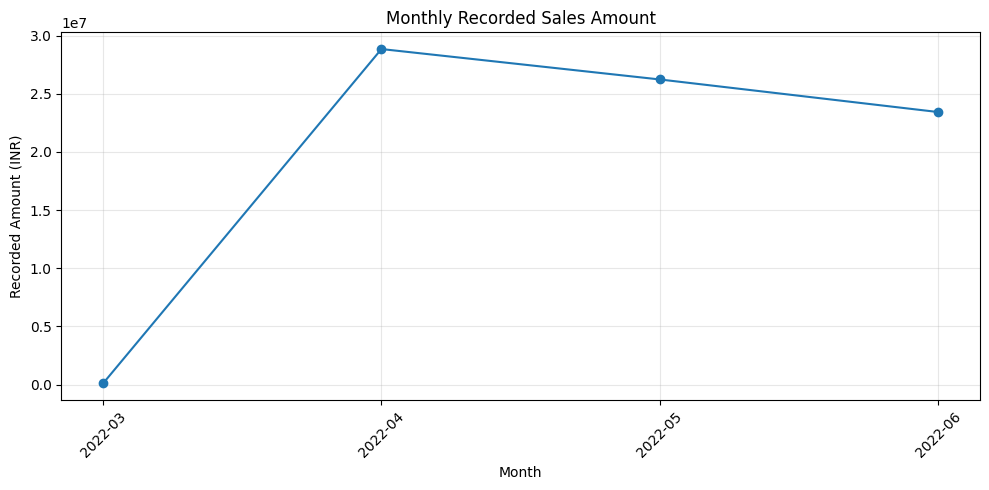

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_analysis["month"],
    monthly_analysis["recorded_amount"],
    marker="o"
)

plt.title("Monthly Recorded Sales Amount")
plt.xlabel("Month")
plt.ylabel("Recorded Amount (INR)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
monthly_orders = df_analysis.groupby(
    [df_analysis["date"].dt.to_period("M"), "order_id"]
).agg(
    status=("status", "first")
).reset_index()

monthly_orders["is_cancelled"] = (
    monthly_orders["status"] == "Cancelled"
).astype(int)

monthly_cancellation = monthly_orders.groupby("date").agg(
    total_orders=("order_id", "nunique"),
    cancelled_orders=("is_cancelled", "sum")
).reset_index()

monthly_cancellation["cancellation_rate"] = (
    monthly_cancellation["cancelled_orders"]
    / monthly_cancellation["total_orders"] * 100
).round(2)

monthly_cancellation["month"] = (
    monthly_cancellation["date"].astype(str)
)

display(monthly_cancellation)

,date,total_orders,cancelled_orders,cancellation_rate,month
0,2022-03,158,18,11.39,2022-03
1,2022-04,45858,6726,14.67,2022-04
2,2022-05,39221,5484,13.98,2022-05
3,2022-06,35141,4957,14.11,2022-06


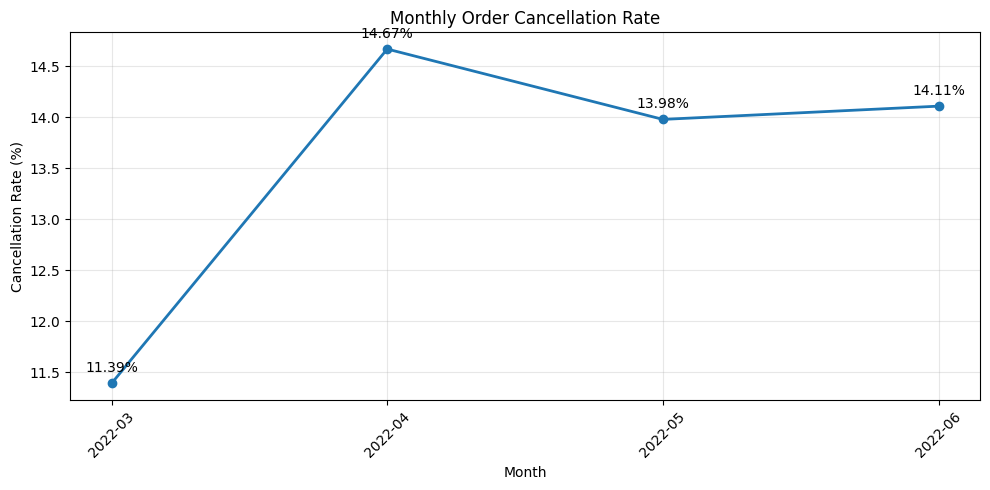

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_cancellation["month"],
    monthly_cancellation["cancellation_rate"],
    marker="o",
    linewidth=2
)

for x, y in zip(
    monthly_cancellation["month"],
    monthly_cancellation["cancellation_rate"]
):
    plt.annotate(
        f"{y:.2f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.title("Monthly Order Cancellation Rate")
plt.xlabel("Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
category_analysis = df_analysis.groupby("category").agg(
    product_records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    total_quantity=("qty", "sum"),
    recorded_amount=("amount", "sum")
).reset_index()

category_analysis["recorded_amount"] = (
    category_analysis["recorded_amount"].round(2)
)

category_analysis = category_analysis.sort_values(
    "recorded_amount", ascending=False
)

display(category_analysis)

,category,product_records,unique_orders,total_quantity,recorded_amount
5,Set,50281,47845,45287,39202022.03
8,kurta,49874,46561,45044,21299013.70
7,Western Dress,15500,14994,13943,11216072.69
6,Top,10622,10155,9903,5347792.30
3,Ethnic Dress,1159,1148,1053,791217.66
0,Blouse,926,897,863,458408.18
1,Bottom,440,410,398,150667.98
4,Saree,164,144,152,123933.76
2,Dupatta,3,2,3,915.00


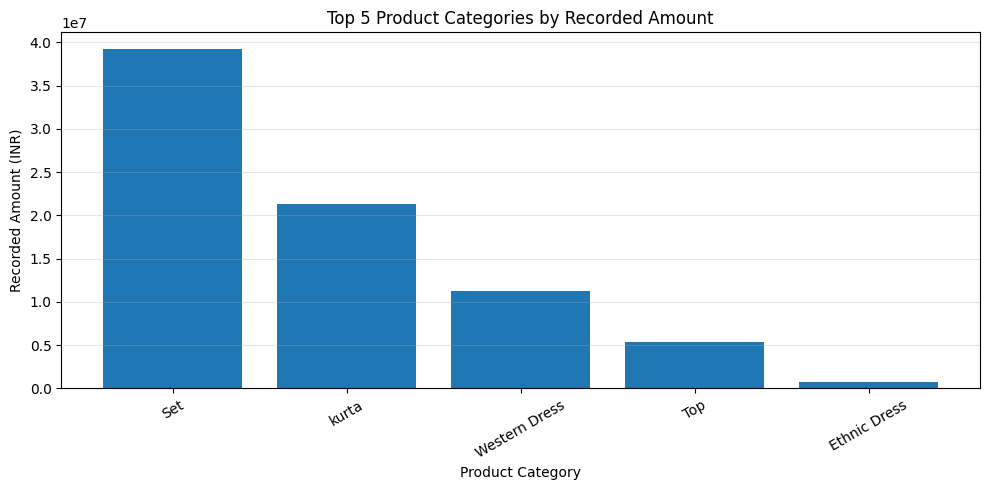

In [30]:
top_categories = category_analysis.head(5)

plt.figure(figsize=(10, 5))

plt.bar(
    top_categories["category"],
    top_categories["recorded_amount"]
)

plt.title("Top 5 Product Categories by Recorded Amount")
plt.xlabel("Product Category")
plt.ylabel("Recorded Amount (INR)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
size_analysis = df_analysis.groupby("size").agg(
    product_records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    total_quantity=("qty", "sum"),
    recorded_amount=("amount", "sum")
).reset_index()

size_analysis = size_analysis.sort_values(
    "total_quantity", ascending=False
)

display(size_analysis)

,size,product_records,unique_orders,total_quantity,recorded_amount
6,M,22709,21722,20446,13905591.37
5,L,22130,21058,20000,13234886.19
8,XL,20875,19896,18922,12464026.86
10,XXL,18096,17164,16516,10636288.45
7,S,17090,16336,15331,10629210.18
0,3XL,14815,13755,13523,9156614.68
9,XS,11161,10533,9943,7022375.20
3,6XL,738,681,688,576249.33
2,5XL,550,526,513,425156.63
1,4XL,427,394,398,334451.64


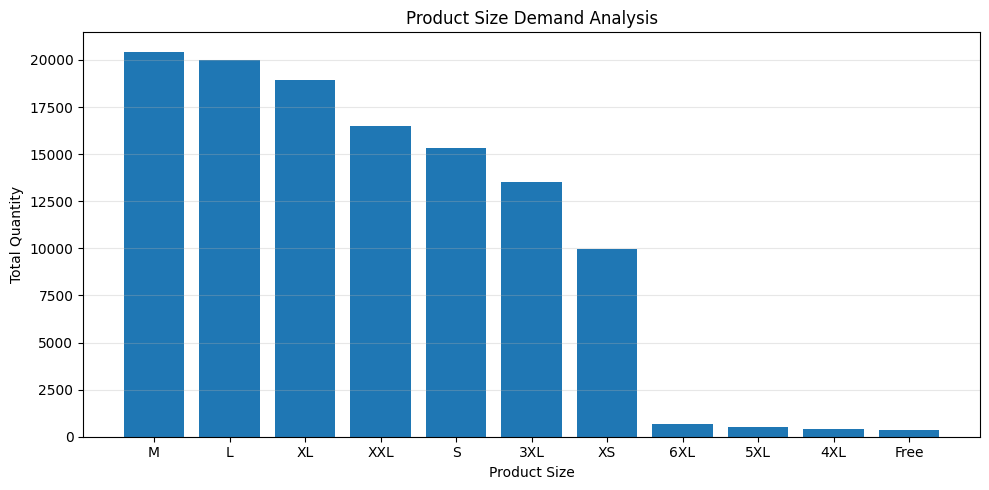

In [32]:
plt.figure(figsize=(10, 5))

plt.bar(
    size_analysis["size"],
    size_analysis["total_quantity"]
)

plt.title("Product Size Demand Analysis")
plt.xlabel("Product Size")
plt.ylabel("Total Quantity")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
state_analysis = df_analysis.groupby("ship_state").agg(
    product_records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    total_quantity=("qty", "sum"),
    recorded_amount=("amount", "sum")
).reset_index()

state_analysis = state_analysis.sort_values(
    "recorded_amount", ascending=False
)

display(state_analysis.head(15))

,ship_state,product_records,unique_orders,total_quantity,recorded_amount
28,MAHARASHTRA,22259,20780,20327,13334595.14
23,KARNATAKA,17325,16182,15901,10481114.37
57,TELANGANA,11330,10405,10253,6916615.65
59,UTTAR PRADESH,10637,10062,9498,6816109.08
56,TAMIL NADU,11483,10519,10412,6515650.11
14,DELHI,6782,6359,6156,4235215.97
24,KERALA,6584,6105,5813,3830227.58
61,WEST BENGAL,5962,5653,5318,3507880.44
1,ANDHRA PRADESH,5430,4979,4819,3219831.72
19,HARYANA,4415,4142,4066,2882092.99


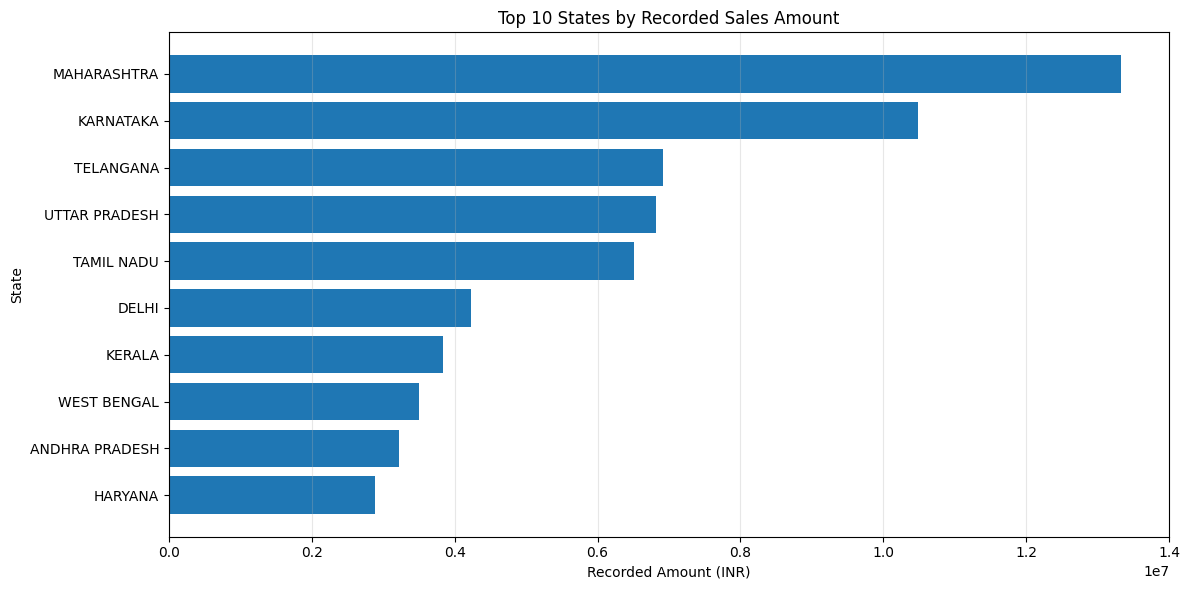

In [34]:
top_states = state_analysis.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_states["ship_state"],
    top_states["recorded_amount"]
)

plt.title("Top 10 States by Recorded Sales Amount")
plt.xlabel("Recorded Amount (INR)")
plt.ylabel("State")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
fulfilment_analysis = order_level.groupby("fulfilment").agg(
    total_orders=("order_id", "nunique"),
    cancelled_orders=("status", lambda x: (x == "Cancelled").sum())
).reset_index()

fulfilment_analysis["cancellation_rate"] = (
    fulfilment_analysis["cancelled_orders"]
    / fulfilment_analysis["total_orders"] * 100
).round(2)

display(fulfilment_analysis)

,fulfilment,total_orders,cancelled_orders,cancellation_rate
0,Amazon,84002,10803,12.86
1,Merchant,36376,6382,17.54


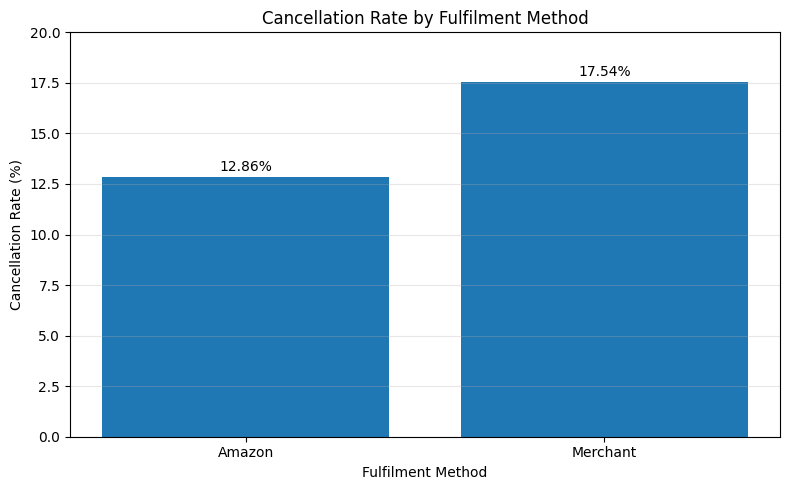

In [36]:
plt.figure(figsize=(8, 5))

plt.bar(
    fulfilment_analysis["fulfilment"],
    fulfilment_analysis["cancellation_rate"]
)

plt.title("Cancellation Rate by Fulfilment Method")
plt.xlabel("Fulfilment Method")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 20)
plt.grid(axis="y", alpha=0.3)

for x, y in enumerate(fulfilment_analysis["cancellation_rate"]):
    plt.text(x, y + 0.3, f"{y:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [37]:
courier_analysis = df_analysis.groupby(
    ["fulfilment", "courier_status"],
    dropna=False
).agg(
    product_records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    total_quantity=("qty", "sum")
).reset_index()

display(courier_analysis)

,fulfilment,courier_status,product_records,unique_orders,total_quantity
0,Amazon,Cancelled,5932,5665,0
1,Amazon,Shipped,77603,72719,77858
2,Amazon,Unshipped,6157,5714,6226
3,Merchant,Shipped,31881,29513,32035
4,Merchant,Unshipped,524,481,527
5,Merchant,NaN,6872,6393,0


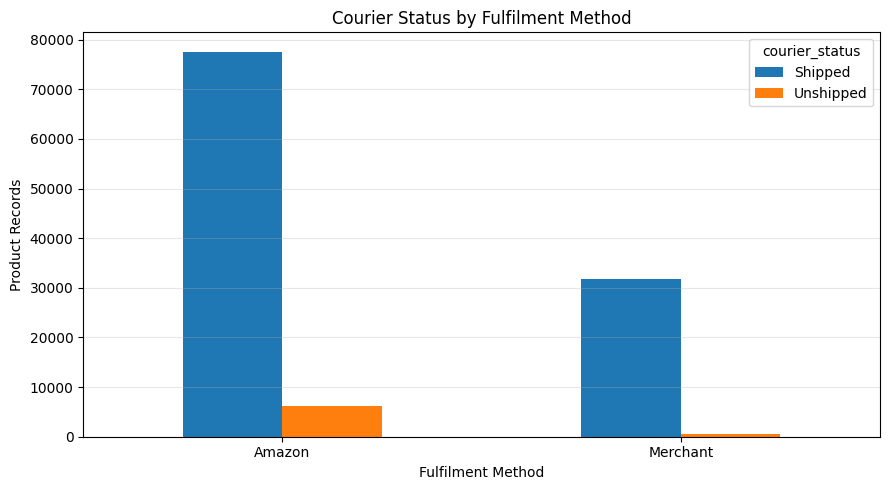

In [38]:
courier_plot = courier_analysis[
    courier_analysis["courier_status"].isin(["Shipped", "Unshipped"])
]

courier_pivot = courier_plot.pivot(
    index="fulfilment",
    columns="courier_status",
    values="product_records"
)

courier_pivot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Courier Status by Fulfilment Method")
plt.xlabel("Fulfilment Method")
plt.ylabel("Product Records")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
amount_analysis = df_analysis[
    df_analysis["amount"].notna() &
    (df_analysis["amount"] > 0)
].copy()

print("Order amount summary:")
display(amount_analysis["amount"].describe().round(2))

Order amount summary:


count    118834.00
mean        661.34
std         268.67
min         199.00
25%         458.00
50%         622.00
75%         788.00
max        5584.00
Name: amount, dtype: float64

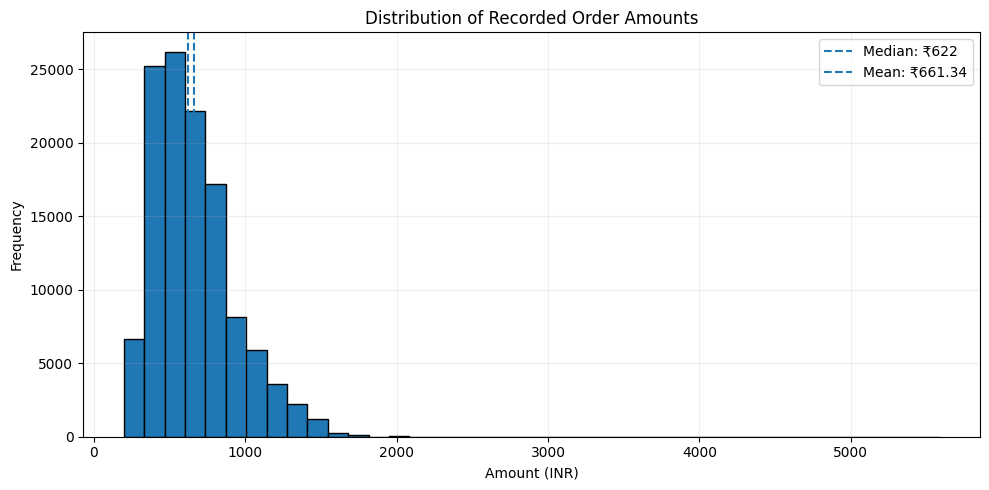

In [40]:
plt.figure(figsize=(10, 5))

plt.hist(
    amount_analysis["amount"],
    bins=40,
    edgecolor="black"
)

plt.axvline(
    amount_analysis["amount"].median(),
    linestyle="--",
    label="Median: ₹622"
)

plt.axvline(
    amount_analysis["amount"].mean(),
    linestyle="--",
    label="Mean: ₹661.34"
)

plt.title("Distribution of Recorded Order Amounts")
plt.xlabel("Amount (INR)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [41]:
Q1 = amount_analysis["amount"].quantile(0.25)
Q3 = amount_analysis["amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = amount_analysis[
    (amount_analysis["amount"] < lower_bound) |
    (amount_analysis["amount"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outlier records:", len(outliers))
print("Outlier percentage:", round(len(outliers) / len(amount_analysis) * 100, 2), "%")

Q1: 458.0
Q3: 788.0
IQR: 330.0
Lower bound: -37.0
Upper bound: 1283.0
Number of outlier records: 3743
Outlier percentage: 3.15 %


In [42]:
top_value_records = outliers.sort_values(
    "amount", ascending=False
)[[
    "order_id",
    "date",
    "category",
    "sku",
    "qty",
    "amount",
    "ship_state",
    "status"
]]

display(top_value_records.head(10))

,order_id,date,category,sku,qty,amount,ship_state,status
42039,402-5239558-4281957,2022-04-05,Set,SET268-KR-NP-XS,8,5584.00,ANDHRA PRADESH,Shipped
11160,403-4106553-1691525,2022-04-23,Set,J0013-SKD-XXXL,5,5495.00,PUNJAB,Shipped - Delivered to Buyer
24494,407-3483041-9133135,2022-04-16,Set,SET397-KR-NP -M,0,4235.72,RAJASTHAN,Cancelled
89150,406-7195963-2374765,2022-05-02,Set,SET197-KR-NP-M,4,3036.00,UTTAR PRADESH,Shipped
121225,404-4712917-7300332,2022-06-06,Set,SET278-KR-NP-XXXL,2,2894.00,MAHARASHTRA,Shipped
28814,408-9885439-6698733,2022-04-13,Set,J0285-SKD-S,2,2864.00,KARNATAKA,Shipped
39944,408-3363121-6123562,2022-04-06,Western Dress,JNE3797-KR-XS,4,2860.00,UTTAR PRADESH,Shipped - Delivered to Buyer
79899,405-6877720-7865168,2022-05-07,kurta,JNE2086-KR-389-M,4,2796.00,HARYANA,Shipped - Returned to Seller
63974,408-9361250-7029128,2022-05-19,Set,J0230-SKD-XL,2,2698.00,WEST BENGAL,Shipped
75760,402-9141667-1791537,2022-05-10,Set,SET364-KR-NP-XXL,2,2676.00,TAMIL NADU,Cancelled


In [43]:
outlier_status = outliers.groupby("status").agg(
    outlier_records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    recorded_amount=("amount", "sum")
).reset_index()

outlier_status = outlier_status.sort_values(
    "outlier_records", ascending=False
)

display(outlier_status)

,status,outlier_records,unique_orders,recorded_amount
3,Shipped,2439,2387,3482816.00
4,Shipped - Delivered to Buyer,900,889,1288586.00
0,Cancelled,253,249,362151.88
7,Shipped - Returned to Seller,69,66,100974.00
6,Shipped - Picked Up,36,35,51228.00
1,Pending,27,27,38399.00
8,Shipped - Returning to Seller,8,8,11994.00
2,Pending - Waiting for Pick Up,7,7,10743.00
5,Shipped - Out for Delivery,4,4,5584.00


In [110]:
outliers = amount_analysis[
    (amount_analysis["amount"] < lower_bound) |
    (amount_analysis["amount"] > upper_bound)
].copy()

print("Outlier records:", len(outliers))

Outlier records: 3743


In [113]:
outliers.loc[:, "month"] = outliers["date"].dt.to_period("M").astype(str)

display(outliers.head())

,order_id,date,status,fulfilment,sales_channel,ship_service_level,style,sku,category,size,...,promotion_ids,b2b,fulfilled_by,amount_missing,currency_missing,courier_status_missing,zero_quantity,zero_amount,location_missing,month
102,408-7698765-2294756,2022-04-30,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,SET277,SET277-KR-NP-XXL,Set,XXL,...,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,False,False,False,False,False,False,2022-04
146,171-0131752-2560336,2022-04-30,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,SET355,SET355-KR-PP-M,Set,M,...,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,False,False,False,False,False,False,2022-04
243,408-2759943-9849959,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,SET363,SET363-KR-NP-XXL,Set,XXL,...,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,False,False,False,False,False,False,2022-04
265,171-6655820-6440356,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,J0008,J0008-SKD-XXL,Set,XXL,...,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,False,False,False,False,False,False,2022-04
299,404-7491342-1035558,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,J0280,J0280-SKD-S,Set,S,...,NaN,False,NaN,False,False,False,False,False,False,2022-04


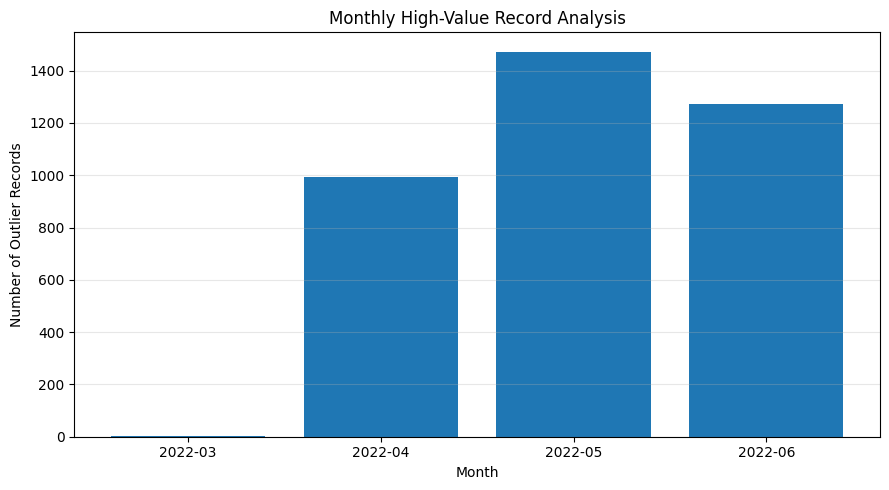

In [114]:
plt.figure(figsize=(9, 5))

plt.bar(
    monthly_outliers["month"],
    monthly_outliers["outlier_records"]
)

plt.title("Monthly High-Value Record Analysis")
plt.xlabel("Month")
plt.ylabel("Number of Outlier Records")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [115]:
sku_analysis = df_analysis.groupby(
    ["sku", "category"]
).agg(
    product_records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    total_quantity=("qty", "sum"),
    recorded_amount=("amount", "sum")
).reset_index()

sku_analysis = sku_analysis.sort_values(
    "recorded_amount", ascending=False
)

display(sku_analysis.head(10))

,sku,category,product_records,unique_orders,total_quantity,recorded_amount
1346,J0230-SKD-M,Set,506,506,467,526536.20
4548,JNE3797-KR-L,Western Dress,773,773,661,524581.77
1347,J0230-SKD-S,Set,452,452,421,479937.14
4549,JNE3797-KR-M,Western Dress,657,657,561,454290.16
4550,JNE3797-KR-S,Western Dress,587,587,503,407302.57
4551,JNE3797-KR-XL,Western Dress,474,474,415,332155.24
1345,J0230-SKD-L,Set,297,297,272,305616.95
4552,JNE3797-KR-XS,Western Dress,431,431,386,303616.70
6305,SET268-KR-NP-XL,Set,386,386,373,284058.96
4554,JNE3797-KR-XXXL,Western Dress,386,386,353,276375.80


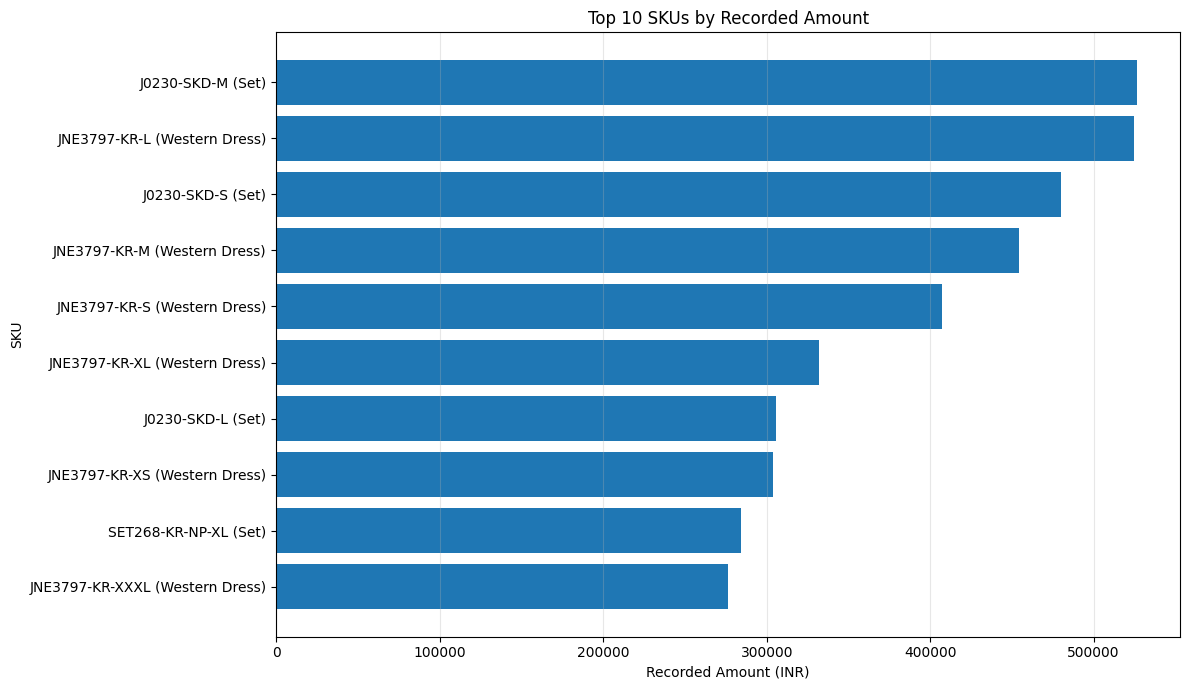

In [116]:
top_skus = sku_analysis.head(10).copy()

top_skus["sku_label"] = (
    top_skus["sku"] + " (" + top_skus["category"] + ")"
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_skus["sku_label"],
    top_skus["recorded_amount"]
)

plt.title("Top 10 SKUs by Recorded Amount")
plt.xlabel("Recorded Amount (INR)")
plt.ylabel("SKU")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [117]:
b2b_analysis = df_analysis.groupby("b2b").agg(
    product_records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    total_quantity=("qty", "sum"),
    recorded_amount=("amount", "sum")
).reset_index()

b2b_analysis["customer_type"] = b2b_analysis["b2b"].map({
    True: "B2B",
    False: "B2C"
})

display(b2b_analysis)

,b2b,product_records,unique_orders,total_quantity,recorded_amount,customer_type
0,False,128098,119584,115806,77998822.51,B2C
1,True,871,794,840,591220.79,B2B


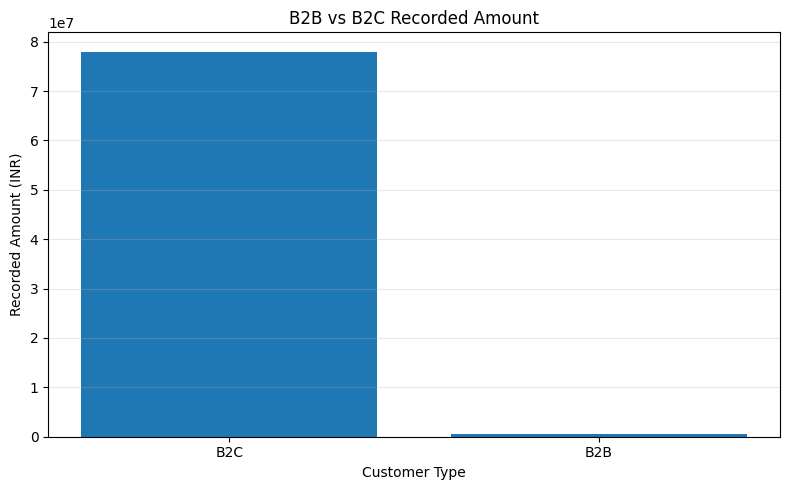

In [118]:
plt.figure(figsize=(8, 5))

plt.bar(
    b2b_analysis["customer_type"],
    b2b_analysis["recorded_amount"]
)

plt.title("B2B vs B2C Recorded Amount")
plt.xlabel("Customer Type")
plt.ylabel("Recorded Amount (INR)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [119]:
df_analysis["promotion_used"] = (
    df_analysis["promotion_ids"].notna()
)

promotion_analysis = df_analysis.groupby("promotion_used").agg(
    product_records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    total_quantity=("qty", "sum"),
    recorded_amount=("amount", "sum")
).reset_index()

promotion_analysis["promotion_type"] = (
    promotion_analysis["promotion_used"]
    .map({True: "Promotion Used", False: "No Promotion Recorded"})
)

display(promotion_analysis)

,promotion_used,product_records,unique_orders,total_quantity,recorded_amount,promotion_type
0,False,49150,46937,36798,25004243.3,No Promotion Recorded
1,True,79819,73464,79848,53585800.0,Promotion Used


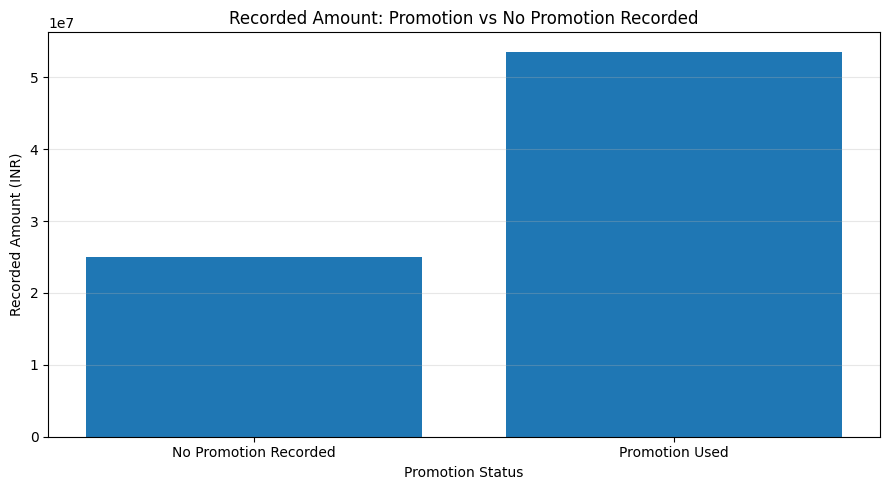

In [120]:
plt.figure(figsize=(9, 5))

plt.bar(
    promotion_analysis["promotion_type"],
    promotion_analysis["recorded_amount"]
)

plt.title("Recorded Amount: Promotion vs No Promotion Recorded")
plt.xlabel("Promotion Status")
plt.ylabel("Recorded Amount (INR)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

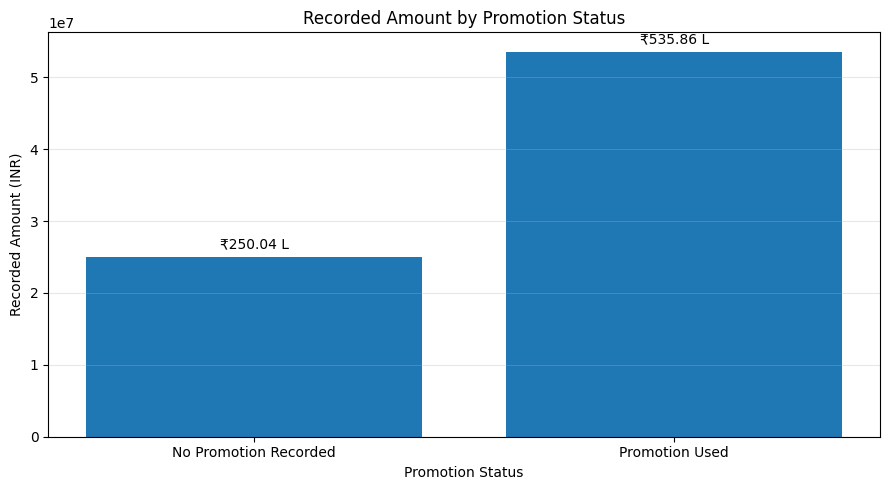

In [121]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    promotion_analysis["promotion_type"],
    promotion_analysis["recorded_amount"]
)

plt.title("Recorded Amount by Promotion Status")
plt.xlabel("Promotion Status")
plt.ylabel("Recorded Amount (INR)")

plt.bar_label(
    bars,
    labels=[
        f"₹{value / 100000:.2f} L"
        for value in promotion_analysis["recorded_amount"]
    ],
    padding=4
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [122]:
city_analysis = df_analysis.groupby("ship_city").agg(
    product_records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    total_quantity=("qty", "sum"),
    recorded_amount=("amount", "sum")
).reset_index()

city_analysis = city_analysis.sort_values(
    "recorded_amount", ascending=False
)

display(city_analysis.head(10))

,ship_city,product_records,unique_orders,total_quantity,recorded_amount
776,BENGALURU,11216,10457,10422,6849664.99
2906,HYDERABAD,8074,7411,7333,4946032.82
4795,MUMBAI,6126,5655,5650,3704461.80
5393,NEW DELHI,5795,5436,5252,3613874.78
1466,CHENNAI,5421,4925,4937,3098745.74
6158,PUNE,3856,3594,3532,2337579.18
3712,KOLKATA,2381,2249,2166,1414978.87
2620,GURUGRAM,1868,1771,1734,1221618.74
7587,THANE,1701,1613,1539,1004355.29
4397,LUCKNOW,1458,1393,1283,933926.34


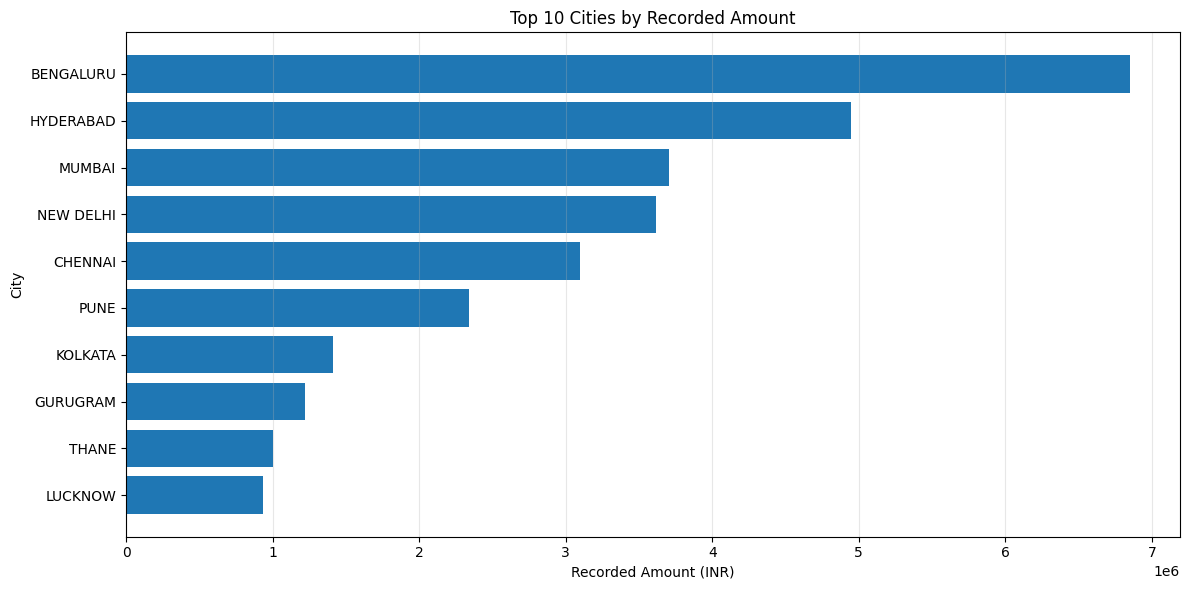

In [123]:
top_cities = city_analysis.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_cities["ship_city"],
    top_cities["recorded_amount"]
)

plt.title("Top 10 Cities by Recorded Amount")
plt.xlabel("Recorded Amount (INR)")
plt.ylabel("City")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [124]:
order_aov = df_analysis.groupby("order_id").agg(
    order_amount=("amount", "sum"),
    status=("status", "first"),
    missing_amounts=("amount", lambda x: x.isna().any())
).reset_index()

valid_orders = order_aov[
    (order_aov["status"] != "Cancelled") &
    (~order_aov["missing_amounts"])
].copy()

valid_orders = valid_orders[
    valid_orders["order_amount"] > 0
]

aov = valid_orders["order_amount"].mean()

print("Valid orders:", len(valid_orders))
print("Average Order Value: ₹", round(aov, 2))
print("Median Order Value: ₹", round(valid_orders["order_amount"].median(), 2))

Valid orders: 100630
Average Order Value: ₹ 711.44
Median Order Value: ₹ 641.0


In [125]:
valid_orders["month"] = (
    valid_orders["order_id"]
    .map(df_analysis.drop_duplicates("order_id").set_index("order_id")["date"])
    .pipe(pd.to_datetime)
    .dt.to_period("M").astype(str)
)

monthly_aov = valid_orders.groupby("month").agg(
    total_orders=("order_id", "nunique"),
    average_order_value=("order_amount", "mean"),
    median_order_value=("order_amount", "median")
).reset_index()

monthly_aov = monthly_aov.round(2)

display(monthly_aov)

,month,total_orders,average_order_value,median_order_value
0,2022-03,139,674.24,599.0
1,2022-04,38209,685.83,599.0
2,2022-05,32918,726.78,655.0
3,2022-06,29364,727.76,671.0


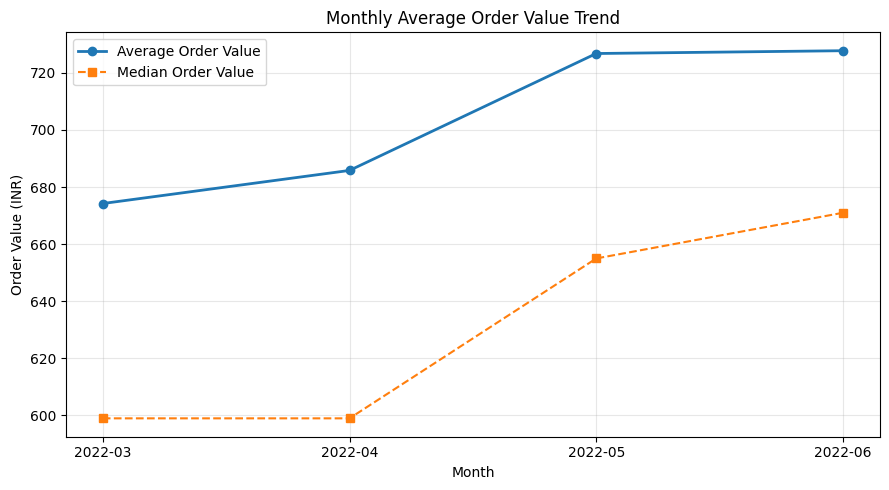

In [126]:
plt.figure(figsize=(9, 5))

plt.plot(
    monthly_aov["month"],
    monthly_aov["average_order_value"],
    marker="o",
    linewidth=2,
    label="Average Order Value"
)

plt.plot(
    monthly_aov["month"],
    monthly_aov["median_order_value"],
    marker="s",
    linestyle="--",
    label="Median Order Value"
)

plt.title("Monthly Average Order Value Trend")
plt.xlabel("Month")
plt.ylabel("Order Value (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [127]:
category_contribution = category_analysis.copy()

total_amount = category_contribution["recorded_amount"].sum()

category_contribution["contribution_pct"] = (
    category_contribution["recorded_amount"]
    / total_amount * 100
).round(2)

category_contribution = category_contribution.sort_values(
    "contribution_pct", ascending=False
)

display(category_contribution[
    ["category", "recorded_amount", "contribution_pct"]
])

,category,recorded_amount,contribution_pct
5,Set,39202022.03,49.88
8,kurta,21299013.70,27.10
7,Western Dress,11216072.69,14.27
6,Top,5347792.30,6.80
3,Ethnic Dress,791217.66,1.01
0,Blouse,458408.18,0.58
1,Bottom,150667.98,0.19
4,Saree,123933.76,0.16
2,Dupatta,915.00,0.00


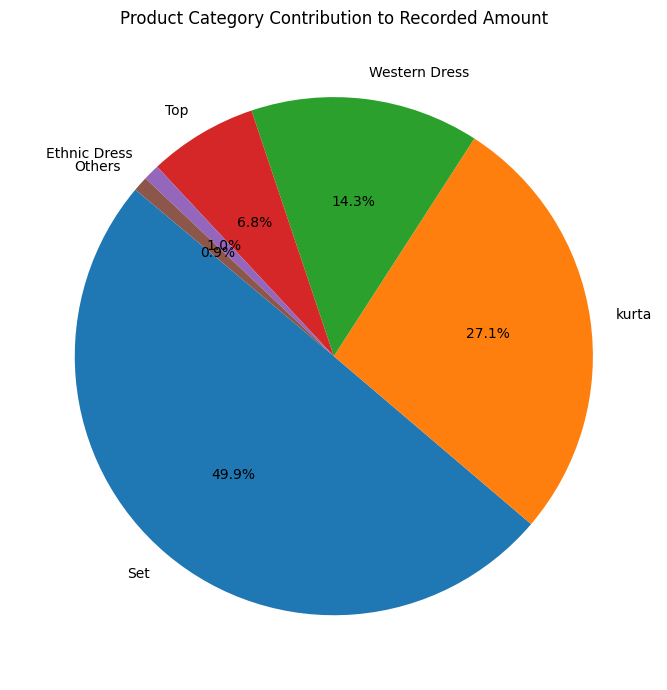

In [128]:
category_pie = category_contribution[
    category_contribution["contribution_pct"] >= 1
].copy()

other_pct = category_contribution.loc[
    category_contribution["contribution_pct"] < 1,
    "contribution_pct"
].sum()

category_pie = pd.concat([
    category_pie[["category", "contribution_pct"]],
    pd.DataFrame([{
        "category": "Others",
        "contribution_pct": other_pct
    }])
], ignore_index=True)

plt.figure(figsize=(9, 7))

plt.pie(
    category_pie["contribution_pct"],
    labels=category_pie["category"],
    autopct="%1.1f%%",
    startangle=140
)

plt.title("Product Category Contribution to Recorded Amount")
plt.tight_layout()
plt.show()

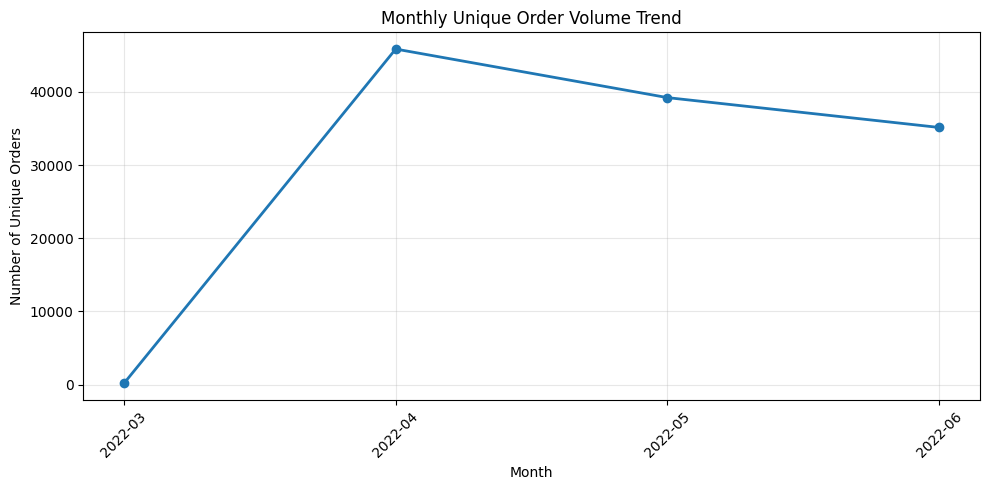

In [129]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_analysis["month"],
    monthly_analysis["unique_orders"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Unique Order Volume Trend")
plt.xlabel("Month")
plt.ylabel("Number of Unique Orders")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

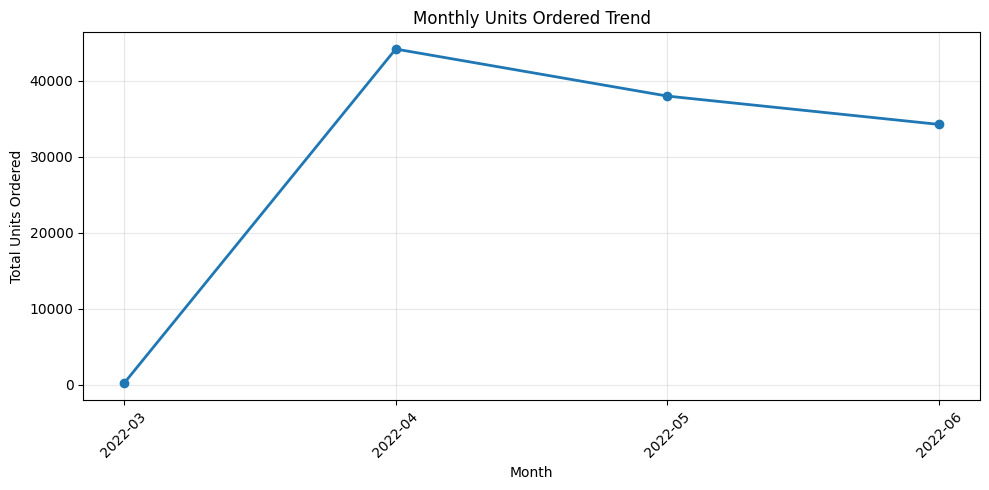

In [130]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_analysis["month"],
    monthly_analysis["total_quantity"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Units Ordered Trend")
plt.xlabel("Month")
plt.ylabel("Total Units Ordered")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [132]:
monthly_fulfilment = df_analysis.groupby(
    [df_analysis["date"].dt.to_period("M"), "fulfilment"]
).agg(
    unique_orders=("order_id", "nunique")
).reset_index()

monthly_fulfilment["month"] = (
    monthly_fulfilment["date"].astype(str)
)

display(monthly_fulfilment)

,date,fulfilment,unique_orders,month
0,2022-03,Amazon,135,2022-03
1,2022-03,Merchant,23,2022-03
2,2022-04,Amazon,31291,2022-04
3,2022-04,Merchant,14567,2022-04
4,2022-05,Amazon,26879,2022-05
5,2022-05,Merchant,12342,2022-05
6,2022-06,Amazon,25697,2022-06
7,2022-06,Merchant,9444,2022-06


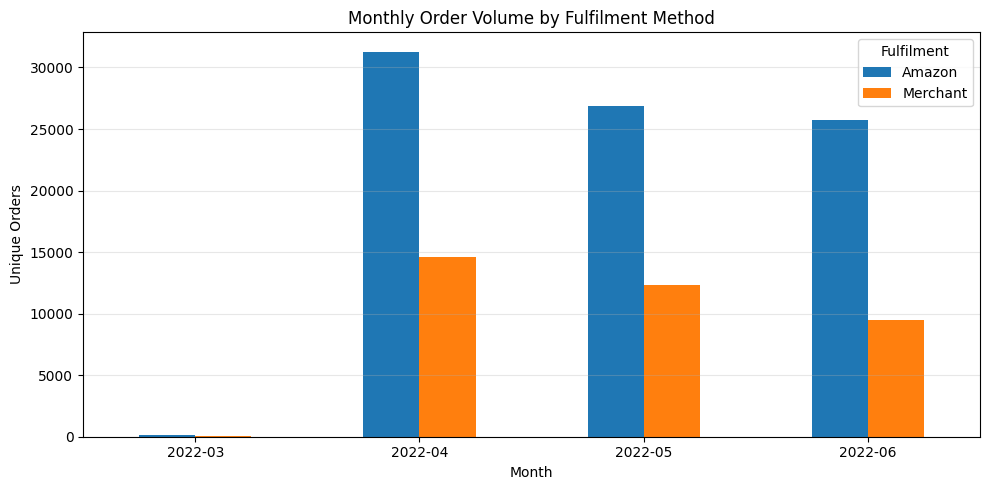

In [133]:
fulfilment_pivot = monthly_fulfilment.pivot(
    index="month",
    columns="fulfilment",
    values="unique_orders"
)

fulfilment_pivot.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Monthly Order Volume by Fulfilment Method")
plt.xlabel("Month")
plt.ylabel("Unique Orders")
plt.xticks(rotation=0)
plt.legend(title="Fulfilment")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [134]:
monthly_cancel = order_level.copy()

monthly_cancel["month"] = (
    monthly_cancel["order_id"]
    .map(
        df_analysis.drop_duplicates("order_id")
        .set_index("order_id")["date"]
    )
    .pipe(pd.to_datetime)
    .dt.to_period("M").astype(str)
)

monthly_cancel["is_cancelled"] = (
    monthly_cancel["status"] == "Cancelled"
).astype(int)

monthly_cancel_analysis = monthly_cancel.groupby(
    ["month", "fulfilment"]
).agg(
    total_orders=("order_id", "nunique"),
    cancelled_orders=("is_cancelled", "sum")
).reset_index()

monthly_cancel_analysis["cancellation_rate"] = (
    monthly_cancel_analysis["cancelled_orders"]
    / monthly_cancel_analysis["total_orders"] * 100
).round(2)

display(monthly_cancel_analysis)

,month,fulfilment,total_orders,cancelled_orders,cancellation_rate
0,2022-03,Amazon,135,12,8.89
1,2022-03,Merchant,23,6,26.09
2,2022-04,Amazon,31291,4114,13.15
3,2022-04,Merchant,14567,2612,17.93
4,2022-05,Amazon,26879,3369,12.53
5,2022-05,Merchant,12342,2115,17.14
6,2022-06,Amazon,25697,3308,12.87
7,2022-06,Merchant,9444,1649,17.46


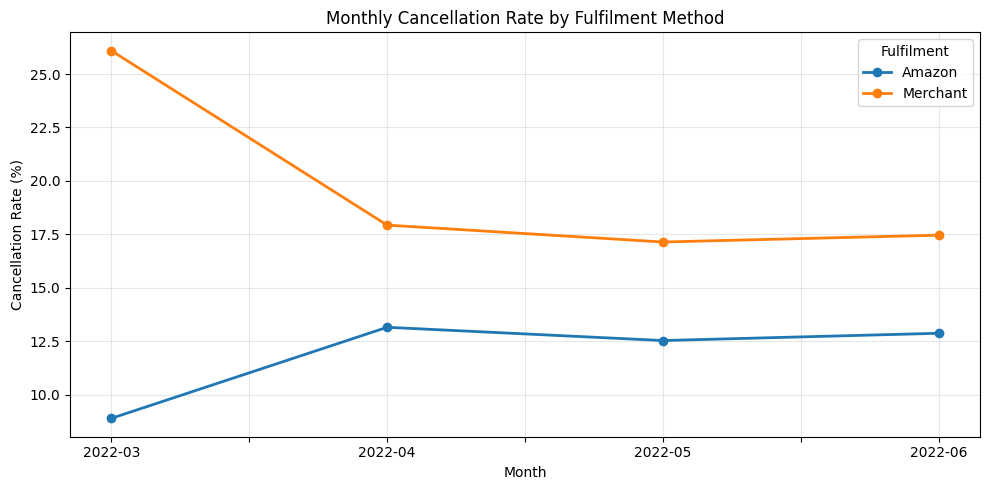

In [135]:
cancellation_pivot = monthly_cancel_analysis.pivot(
    index="month",
    columns="fulfilment",
    values="cancellation_rate"
)

cancellation_pivot.plot(
    kind="line",
    marker="o",
    linewidth=2,
    figsize=(10, 5)
)

plt.title("Monthly Cancellation Rate by Fulfilment Method")
plt.xlabel("Month")
plt.ylabel("Cancellation Rate (%)")
plt.legend(title="Fulfilment")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [136]:
state_orders = df_analysis[
    ["order_id", "ship_state", "status"]
].drop_duplicates()

state_cancellation = state_orders.groupby("ship_state").agg(
    total_orders=("order_id", "nunique"),
    cancelled_orders=("status", lambda x: (x == "Cancelled").sum())
).reset_index()

state_cancellation["cancellation_rate"] = (
    state_cancellation["cancelled_orders"]
    / state_cancellation["total_orders"] * 100
).round(2)

state_cancellation = state_cancellation[
    state_cancellation["total_orders"] >= 100
].sort_values("cancellation_rate", ascending=False)

display(state_cancellation.head(15))

,ship_state,total_orders,cancelled_orders,cancellation_rate
20,HIMACHAL PRADESH,750,144,19.20
0,ANDAMAN & NICOBAR,242,44,18.18
24,KERALA,6105,1086,17.79
21,JAMMU & KASHMIR,670,117,17.46
43,PUDUCHERRY,308,51,16.56
8,BIHAR,1989,327,16.44
1,ANDHRA PRADESH,4979,815,16.37
22,JHARKHAND,1382,226,16.35
30,MEGHALAYA,191,31,16.23
39,ODISHA,2000,322,16.10


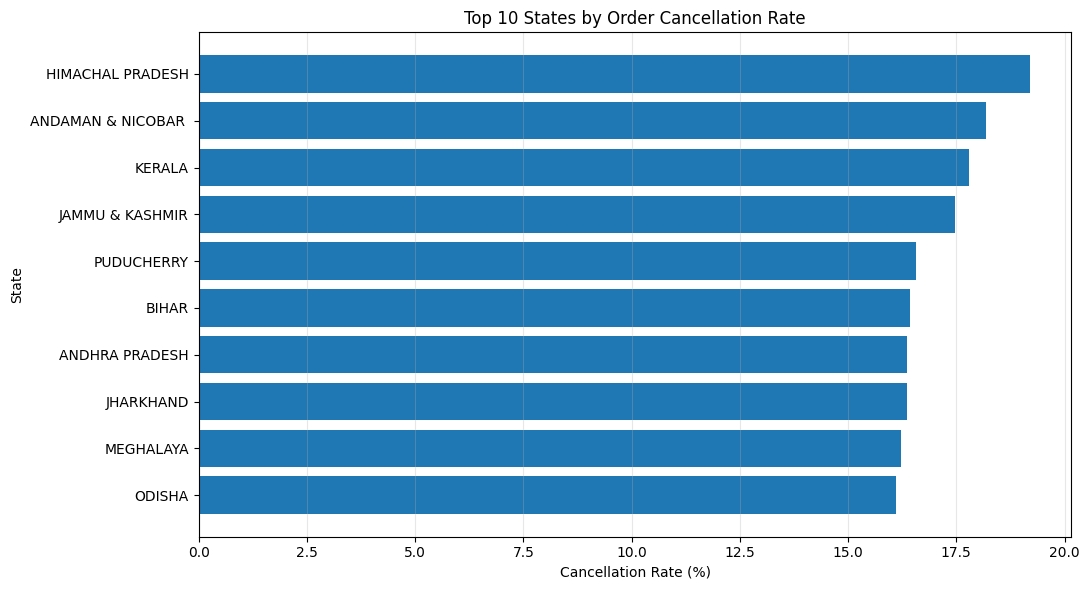

In [137]:
top_cancel_states = state_cancellation.head(10).copy()

plt.figure(figsize=(11, 6))

plt.barh(
    top_cancel_states["ship_state"],
    top_cancel_states["cancellation_rate"]
)

plt.title("Top 10 States by Order Cancellation Rate")
plt.xlabel("Cancellation Rate (%)")
plt.ylabel("State")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [138]:
service_orders = df_analysis.groupby("order_id").agg(
    ship_service_level=("ship_service_level", "nunique"),
    service_level=("ship_service_level", "first"),
    status=("status", "first")
).reset_index()

print("Orders with multiple service levels:",
      (service_orders["ship_service_level"] > 1).sum())

service_cancellation = service_orders.groupby("service_level").agg(
    total_orders=("order_id", "nunique"),
    cancelled_orders=("status", lambda x: (x == "Cancelled").sum())
).reset_index()

service_cancellation["cancellation_rate"] = (
    service_cancellation["cancelled_orders"]
    / service_cancellation["total_orders"] * 100
).round(2)

display(service_cancellation)

Orders with multiple service levels: 0


,service_level,total_orders,cancelled_orders,cancellation_rate
0,Expedited,82922,10756,12.97
1,Standard,37456,6429,17.16


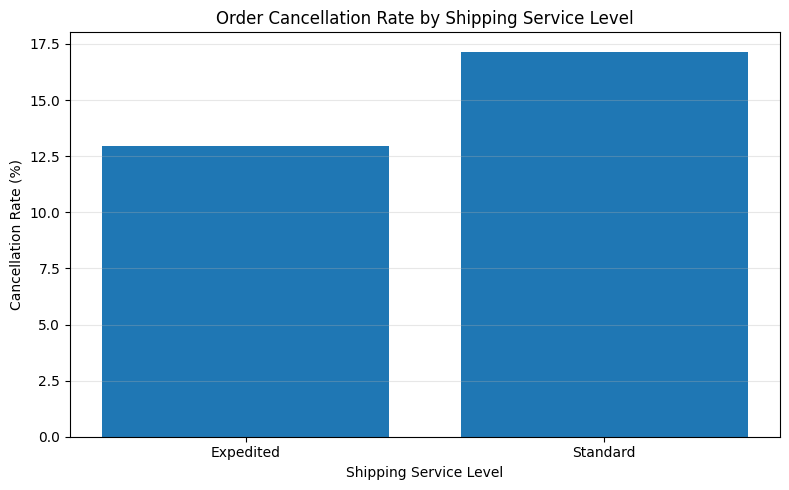

In [139]:
plt.figure(figsize=(8, 5))

plt.bar(
    service_cancellation["service_level"],
    service_cancellation["cancellation_rate"]
)

plt.title("Order Cancellation Rate by Shipping Service Level")
plt.xlabel("Shipping Service Level")
plt.ylabel("Cancellation Rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [140]:
print("PROJECT SUMMARY")
print("-" * 40)

print("Product records:", len(df_analysis))
print("Unique orders:", df_analysis["order_id"].nunique())
print("Total quantity:", df_analysis["qty"].sum())
print("Recorded amount: ₹{:,.2f}".format(df_analysis["amount"].sum()))

print("\nOverall cancellation rate: {:.2f}%".format(
    order_level["status"].eq("Cancelled").mean() * 100
))

print("Average order value: ₹{:,.2f}".format(valid_orders["order_amount"].mean()))

print("\nTop category:", category_analysis.iloc[0]["category"])
print("Top state:", state_analysis.iloc[0]["ship_state"])

PROJECT SUMMARY
----------------------------------------
Product records: 128969
Unique orders: 120378
Total quantity: 116646
Recorded amount: ₹78,590,043.30

Overall cancellation rate: 14.28%
Average order value: ₹711.44

Top category: Set
Top state: MAHARASHTRA


In [142]:
import plotly
import ipywidgets

print("Plotly:", plotly.__version__)
print("ipywidgets:", ipywidgets.__version__)

Plotly: 5.24.1
ipywidgets: 8.1.5


In [143]:
dashboard_df = df_analysis.copy()

dashboard_df["month"] = (
    dashboard_df["date"].dt.to_period("M").astype(str)
)

dashboard_df["status"] = dashboard_df["status"].fillna("Unknown")
dashboard_df["category"] = dashboard_df["category"].fillna("Unknown")
dashboard_df["ship_state"] = dashboard_df["ship_state"].fillna("Unknown")

print("Dashboard data ready!")
print("Records:", len(dashboard_df))
print("Orders:", dashboard_df["order_id"].nunique())
print("Months:", sorted(dashboard_df["month"].unique()))

Dashboard data ready!
Records: 128969
Orders: 120378
Months: ['2022-03', '2022-04', '2022-05', '2022-06']


In [144]:
import ipywidgets as widgets
from IPython.display import display

month_filter = widgets.SelectMultiple(
    options=sorted(dashboard_df["month"].unique()),
    value=tuple(sorted(dashboard_df["month"].unique())),
    description="Month:",
    layout=widgets.Layout(width="350px", height="100px")
)

category_filter = widgets.SelectMultiple(
    options=sorted(dashboard_df["category"].unique()),
    value=tuple(sorted(dashboard_df["category"].unique())),
    description="Category:",
    layout=widgets.Layout(width="350px", height="130px")
)

fulfilment_filter = widgets.SelectMultiple(
    options=sorted(dashboard_df["fulfilment"].dropna().unique()),
    value=tuple(sorted(dashboard_df["fulfilment"].dropna().unique())),
    description="Fulfilment:",
    layout=widgets.Layout(width="350px", height="80px")
)

display(month_filter, category_filter, fulfilment_filter)

SelectMultiple(description='Month:', index=(0, 1, 2, 3), layout=Layout(height='100px', width='350px'), options…

SelectMultiple(description='Category:', index=(0, 1, 2, 3, 4, 5, 6, 7, 8), layout=Layout(height='130px', width…

SelectMultiple(description='Fulfilment:', index=(0, 1), layout=Layout(height='80px', width='350px'), options=(…

In [146]:
import plotly.graph_objects as go
from IPython.display import display

def create_kpi_card(title, value):
    fig = go.Figure(go.Indicator(
        mode="number",
        value=value,
        title={"text": title},
        number={"valueformat": ",.0f"}
    ))

    fig.update_layout(
        height=150,
        margin=dict(l=20, r=20, t=40, b=10)
    )
    return fig

display(create_kpi_card("Total Orders", 120378))
display(create_kpi_card("Product Records", 128969))
display(create_kpi_card("Total Quantity", 116646))

In [148]:
import plotly.express as px

def update_dashboard(months, categories, fulfilments):
    filtered = dashboard_df[
        dashboard_df["month"].isin(months) &
        dashboard_df["category"].isin(categories) &
        dashboard_df["fulfilment"].isin(fulfilments)
    ].copy()

    monthly = filtered.groupby("month", as_index=False).agg(
        recorded_amount=("amount", "sum"),
        orders=("order_id", "nunique")
    )

    fig1 = px.line(
        monthly, x="month", y="recorded_amount",
        markers=True,
        title="Monthly Recorded Amount"
    )
    fig1.show()

    order_data = filtered.groupby("order_id").agg(
        status=("status", "first"),
        month=("month", "first")
    ).reset_index()

    cancellation = order_data.groupby("month").agg(
        total_orders=("order_id", "nunique"),
        cancelled=("status", lambda x: (x == "Cancelled").sum())
    ).reset_index()

    cancellation["cancellation_rate"] = (
        cancellation["cancelled"] / cancellation["total_orders"] * 100
    )

    fig2 = px.bar(
        cancellation, x="month", y="cancellation_rate",
        title="Monthly Order Cancellation Rate (%)"
    )
    fig2.show()

dashboard_output = widgets.interactive_output(
    update_dashboard,
    {
        "months": month_filter,
        "categories": category_filter,
        "fulfilments": fulfilment_filter
    }
)

display(dashboard_output)

Output()

In [149]:
category_chart_data = (
    dashboard_df.groupby("category")["amount"]
    .sum()
    .nlargest(10)
    .reset_index()
)

fig = px.bar(
    category_chart_data,
    x="amount",
    y="category",
    orientation="h",
    title="Top 10 Product Categories by Recorded Amount",
    labels={
        "amount": "Recorded Amount (₹)",
        "category": "Product Category"
    },
    text_auto=".2s"
)

fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.show()

In [150]:
state_chart_data = (
    dashboard_df.groupby("ship_state")["amount"]
    .sum()
    .nlargest(10)
    .reset_index()
)

fig = px.bar(
    state_chart_data,
    x="amount",
    y="ship_state",
    orientation="h",
    title="Top 10 States by Recorded Amount",
    labels={
        "amount": "Recorded Amount (₹)",
        "ship_state": "State"
    },
    text_auto=".2s"
)

fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.show()

In [151]:
cancel_data = dashboard_df.groupby("fulfilment").agg(
    total_orders=("order_id", "nunique"),
    cancelled_orders=("status", lambda x: x.eq("Cancelled").sum())
).reset_index()

cancel_data["cancellation_rate"] = (
    cancel_data["cancelled_orders"] /
    cancel_data["total_orders"] * 100
)

fig = px.bar(
    cancel_data,
    x="fulfilment",
    y="cancellation_rate",
    text_auto=".2f",
    title="Order Cancellation Rate by Fulfilment",
    labels={
        "fulfilment": "Fulfilment Method",
        "cancellation_rate": "Cancellation Rate (%)"
    }
)

fig.show()

In [155]:
order_fulfilment = dashboard_df.groupby("order_id").agg(
    fulfilment=("fulfilment", "first"),
    status=("status", "first"),
    month=("month", "first")
).reset_index()

monthly_fulfilment_data = (
    order_fulfilment.groupby(["month", "fulfilment"])
    .size()
    .reset_index(name="total_orders")
)

fig = px.line(
    monthly_fulfilment_data,
    x="month",
    y="total_orders",
    color="fulfilment",
    markers=True,
    title="Monthly Unique Order Volume by Fulfilment"
)

fig.show()

In [156]:
monthly_fulfilment_data = (
    order_fulfilment.groupby(["month", "fulfilment"])
    .size()
    .reset_index(name="total_orders")
)

fig = px.line(
    monthly_fulfilment_data,
    x="month",
    y="total_orders",
    color="fulfilment",
    markers=True,
    title="Monthly Order Volume by Fulfilment Method",
    labels={
        "month": "Month",
        "total_orders": "Unique Orders",
        "fulfilment": "Fulfilment Method"
    }
)

fig.show()

In [157]:
from IPython.display import display, HTML

def update_kpis(months, categories, fulfilments):
    filtered = dashboard_df[
        dashboard_df["month"].isin(months) &
        dashboard_df["category"].isin(categories) &
        dashboard_df["fulfilment"].isin(fulfilments)
    ]

    orders = filtered["order_id"].nunique()
    records = len(filtered)
    quantity = filtered["qty"].sum()
    amount = filtered["amount"].sum()

    display(HTML(f"""
    <div style="display:flex;gap:15px;flex-wrap:wrap;">
      <div style="background:#172554;color:white;padding:20px;border-radius:12px;min-width:150px;">
        <small>Total Orders</small><h2>{orders:,}</h2>
      </div>
      <div style="background:#1e3a8a;color:white;padding:20px;border-radius:12px;min-width:150px;">
        <small>Product Records</small><h2>{records:,}</h2>
      </div>
      <div style="background:#334155;color:white;padding:20px;border-radius:12px;min-width:150px;">
        <small>Total Quantity</small><h2>{quantity:,}</h2>
      </div>
      <div style="background:#0f766e;color:white;padding:20px;border-radius:12px;min-width:150px;">
        <small>Recorded Amount</small><h2>₹{amount:,.0f}</h2>
      </div>
    </div>
    """))

kpi_output = widgets.interactive_output(
    update_kpis,
    {
        "months": month_filter,
        "categories": category_filter,
        "fulfilments": fulfilment_filter
    }
)

display(kpi_output)

Output()

In [158]:
from IPython.display import display, HTML

display(HTML("""
<div style="
    background: linear-gradient(120deg, #111827, #1e40af);
    padding: 30px;
    border-radius: 15px;
    color: white;
    font-family: Arial;
">
    <h1 style="margin:0;">Amazon India | Sales & Operations Dashboard</h1>
    <p style="font-size:15px;">
        E-Commerce Performance Analysis | March – June 2022
    </p>
    <p style="font-size:13px;color:#dbeafe;">
        Analyze order trends, product performance, fulfilment,
        cancellations and regional demand.
    </p>
</div>
"""))

In [159]:
display(HTML("""
<div style="
    background:#f8fafc;
    padding:22px;
    border-left:5px solid #2563eb;
    border-radius:10px;
    color:#1e293b;
">
    <h2>Data Quality & Methodology</h2>
    <ul>
        <li>Removed 6 exact duplicate records.</li>
        <li>Standardized column names and converted dates.</li>
        <li>Checked missing values and zero-quantity records.</li>
        <li>Analyzed cancellations at unique order level.</li>
        <li>Used recorded amount, not verified realized revenue.</li>
        <li>March and June contain partial-month data.</li>
    </ul>
    <p><b>Dataset scope:</b> 128,969 product records and 120,378 unique orders.</p>
</div>
"""))

In [160]:
display(HTML("""
<div style="
    background:#f8fafc;
    padding:22px;
    border-radius:10px;
    color:#1e293b;
">
    <h2>Business Insights & Recommendations</h2>

    <h3>1. High Cancellation Rate</h3>
    <p>14.28% of unique orders were cancelled.
    Investigate cancellation reasons and improve order confirmation processes.</p>

    <h3>2. Shipping Performance</h3>
    <p>Standard shipping had a 17.16% cancellation rate,
    compared with 12.97% for Expedited.
    Investigate the reasons behind this difference.</p>

    <h3>3. Category Concentration</h3>
    <p>The Set category contributed 49.88% of recorded amount.
    Monitor inventory and demand for high-contribution categories.</p>

    <h3>4. Regional Demand</h3>
    <p>Maharashtra recorded the highest amount.
    Consider prioritizing regional demand and inventory planning.</p>

    <h3>5. Customer Segment</h3>
    <p>B2C contributed approximately 99.25% of recorded amount.
    Continue monitoring B2C demand while evaluating B2B opportunities.</p>

    <p><i>These are recommendations based on observed dataset patterns,
    not proven business outcomes.</i></p>
</div>
"""))

In [161]:
with pd.ExcelWriter("Amazon_Sales_Analysis.xlsx", engine="openpyxl") as writer:

    monthly_analysis.to_excel(
        writer, sheet_name="Monthly Analysis", index=False
    )

    category_analysis.to_excel(
        writer, sheet_name="Category Analysis", index=False
    )

    state_analysis.to_excel(
        writer, sheet_name="State Analysis", index=False
    )

    service_cancellation.to_excel(
        writer, sheet_name="Shipping Analysis", index=False
    )

    fulfilment_analysis.to_excel(
        writer, sheet_name="Fulfilment Analysis", index=False
    )

    monthly_aov.to_excel(
        writer, sheet_name="Monthly AOV", index=False
    )

    monthly_outliers.to_excel(
        writer, sheet_name="High Value Records", index=False
    )

print("Excel report created successfully!")

Excel report created successfully!


In [162]:
from IPython.display import FileLink, display

display(FileLink("Amazon_Sales_Analysis.xlsx"))

/kaggle/working/Amazon_Sales_Analysis.xlsx